# Section 3 — Case Study: Turning a Loss-Making Campaign Around

**Dataset:** `22_marketing_cleaned.csv` (2,236 customers after Task 1 preprocessing)
**Clusters:** K-Means k = 4 labels from Section 2, Task 2, loaded from `../SECTION-2/22_cluster_labels.csv` (merged on `ID`, not recomputed)
**Economics:** Contact cost = **3 MU** · Revenue per acceptance = **11 MU**

---

> **Structure**
> - [Part a](#part-a) — Diagnosing the pilot
> - [Part b](#part-b) — Who responds? Statistical tests
> - [Part c](#part-c) — Segment-level view
> - [Part d](#part-d) — Response model & targeting
> - [Part e](#part-e) — Recommendation, uplift, ethics, and memo draft

In [1]:
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from scipy.stats import chi2_contingency, mannwhitneyu, ttest_ind, norm, skew, shapiro
from sklearn.base            import clone
from sklearn.preprocessing   import StandardScaler, OneHotEncoder
from sklearn.impute          import SimpleImputer
from sklearn.compose         import ColumnTransformer
from sklearn.pipeline        import Pipeline
from sklearn.linear_model    import LogisticRegression
from sklearn.ensemble        import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics         import (roc_auc_score, average_precision_score,
                                     roc_curve, precision_recall_curve)
from sklearn.calibration     import calibration_curve

warnings.filterwarnings('ignore')
os.makedirs('plots', exist_ok=True)

# ─── Global constants ─────────────────────────────────────────────────────────
COST    = 3    # MU per contact
REVENUE = 11   # MU per acceptance
P_STAR  = COST / REVENUE          # break-even probability
RS      = 42
FOLDS   = 5
RESULTS = {}                      # key numbers collected for the summary / memo

plt.rcParams.update({
    'figure.dpi': 110, 'font.size': 11,
    'axes.titlesize': 13, 'axes.spines.top': False, 'axes.spines.right': False
})
PAL = ['#e63946','#457b9d','#2a9d8f','#f4a261','#8338ec','#06d6a0']

print(f"Cost per contact      : {COST} MU")
print(f"Revenue per acceptance: {REVENUE} MU")
print(f"Break-even p*         : {P_STAR:.4f}  ({P_STAR*100:.2f}%)")

Cost per contact      : 3 MU
Revenue per acceptance: 11 MU
Break-even p*         : 0.2727  (27.27%)


In [2]:
# Load cleaned data and the Section 2 cluster labels (paths relative to SECTION-3)
def find(fname):
    for p in [fname, os.path.join('..','SECTION-2',fname), os.path.join('SECTION-2',fname)]:
        if os.path.exists(p): return p
    raise FileNotFoundError(fname)
DATA_PATH, CLUSTER_PATH = find('22_marketing_cleaned.csv'), find('22_cluster_labels.csv')

df = pd.read_csv(DATA_PATH, encoding='utf-8-sig')
cl = pd.read_csv(CLUSTER_PATH, encoding='utf-8-sig')
assert {'ID', 'cluster'} <= set(cl.columns), cl.columns
df = df.merge(cl[['ID', 'cluster']], on='ID', how='left', validate='one_to_one')
assert df['cluster'].notna().all(), 'Some customers have no cluster label'
df['cluster'] = df['cluster'].astype(int)

print(f"Loaded: {df.shape[0]} rows × {df.shape[1]} columns (incl. merged 'cluster')")
print(df['Response'].value_counts().rename({0:'Non-responder',1:'Responder'}).to_string())
print(f"\nMissing values per column (non-zero only):\n{df.isnull().sum()[df.isnull().sum()>0].to_string()}")
print("(raw 'Income' is not used; 'Income_Clean' is the imputed version)")

Loaded: 2236 rows × 39 columns (incl. merged 'cluster')
Response
Non-responder    1902
Responder         334

Missing values per column (non-zero only):
Income    24
(raw 'Income' is not used; 'Income_Clean' is the imputed version)


---
<a id='part-a'></a>
## Part (a) — Diagnosing the Pilot Campaign

In [3]:
# ─── Wilson confidence interval for a proportion ─────────────────────────────
def wilson_ci(n, k, alpha=0.05):
    """Returns (lower, upper) Wilson score interval."""
    z      = norm.ppf(1 - alpha/2)
    p      = k / n
    denom  = 1 + z**2 / n
    center = (p + z**2 / (2*n)) / denom
    margin = z * np.sqrt(p*(1-p)/n + z**2/(4*n**2)) / denom
    return max(0.0, center - margin), min(1.0, center + margin)

# ─── Cramér's V (bias-corrected) ─────────────────────────────────────────────
def cramers_v(ct):
    """Bias-corrected Cramér's V from a contingency table. Returns chi2, p, dof, V."""
    chi2, p, dof, _ = chi2_contingency(ct)
    n    = ct.values.sum()
    phi2 = chi2 / n
    r, c = ct.shape
    phi2corr = max(0, phi2 - (c-1)*(r-1)/(n-1))
    rcorr    = r - (r-1)**2/(n-1)
    kcorr    = c - (c-1)**2/(n-1)
    denom    = min(kcorr-1, rcorr-1)
    V = np.sqrt(phi2corr/denom) if denom > 0 else 0.0
    return chi2, p, dof, V

# ─── Rank-biserial correlation r = 2U/(n1*n2) − 1, U computed for responders ─
#     r > 0  ⇔  responders tend to have HIGHER values than non-responders
def rank_biserial(u_resp, n1, n2):
    return 2*u_resp / (n1 * n2) - 1.0

# ─── Cohen's d (pooled SD) for the Welch t-test ───────────────────────────────
def cohens_d(a, b):
    na, nb = len(a), len(b)
    sp = np.sqrt(((na-1)*a.var(ddof=1) + (nb-1)*b.var(ddof=1)) / (na+nb-2))
    return (a.mean() - b.mean()) / sp

# ─── Holm–Bonferroni correction ───────────────────────────────────────────────
def holm_bonferroni(p_values, alpha=0.05):
    """Returns (reject list, Holm-adjusted p-values)."""
    p = np.asarray(p_values, dtype=float)
    m = len(p)
    order = np.argsort(p)
    adj_sorted = np.minimum(1.0, np.maximum.accumulate((m - np.arange(m)) * p[order]))
    adj = np.empty(m); adj[order] = adj_sorted
    return list(adj < alpha), adj

print("Statistical helper functions defined")

Statistical helper functions defined


In [4]:
# ── Part (a)(i): Pilot campaign financials ────────────────────────────────────
n       = len(df)
k       = int(df['Response'].sum())
p_hat   = k / n
lo, hi  = wilson_ci(n, k)

total_cost    = n * COST
total_revenue = k * REVENUE
total_profit  = total_revenue - total_cost

print("=" * 55)
print("  Pilot Campaign — Full Customer Base")
print("=" * 55)
print(f"  Total customers contacted  : {n:>6,}")
print(f"  Accepted (Response=1)      : {k:>6,}")
print(f"  Did not accept (Response=0): {n-k:>6,}")
print()
print(f"  Response rate   : {p_hat:.4f}  ({p_hat*100:.2f}%)")
print(f"  95% Wilson CI   : [{lo:.4f}, {hi:.4f}]  = [{lo*100:.2f}%, {hi*100:.2f}%]")
print()
print(f"  Total cost      : {total_cost:>8,} MU  (= {n} × {COST})")
print(f"  Total revenue   : {total_revenue:>8,} MU  (= {k} × {REVENUE})")
print(f"  NET PROFIT      : {total_profit:>+8,} MU")
print("=" * 55)
RESULTS.update(n=n, k=k, p_hat=p_hat, ci_lo=lo, ci_hi=hi, cost=total_cost,
               revenue=total_revenue, profit_all=total_profit)

  Pilot Campaign — Full Customer Base
  Total customers contacted  :  2,236
  Accepted (Response=1)      :    334
  Did not accept (Response=0):  1,902

  Response rate   : 0.1494  (14.94%)
  95% Wilson CI   : [0.1352, 0.1647]  = [13.52%, 16.47%]

  Total cost      :    6,708 MU  (= 2236 × 3)
  Total revenue   :    3,674 MU  (= 334 × 11)
  NET PROFIT      :   -3,034 MU


For each contacted customer with response probability p:
  E[profit] = p × 11 − 3  >  0   ⇔   p > p* = 3/11 = 0.2727

  Break-even p*            = 27.27%
  Observed response rate   = 14.94%  (95% CI upper bound 16.47% is still < p*)
  Shortfall                = 12.34 percentage points
  Average profit / contact = 0.1494×11 − 3 = -1.3569 MU
  × 2,236 contacts          = -3,034 MU


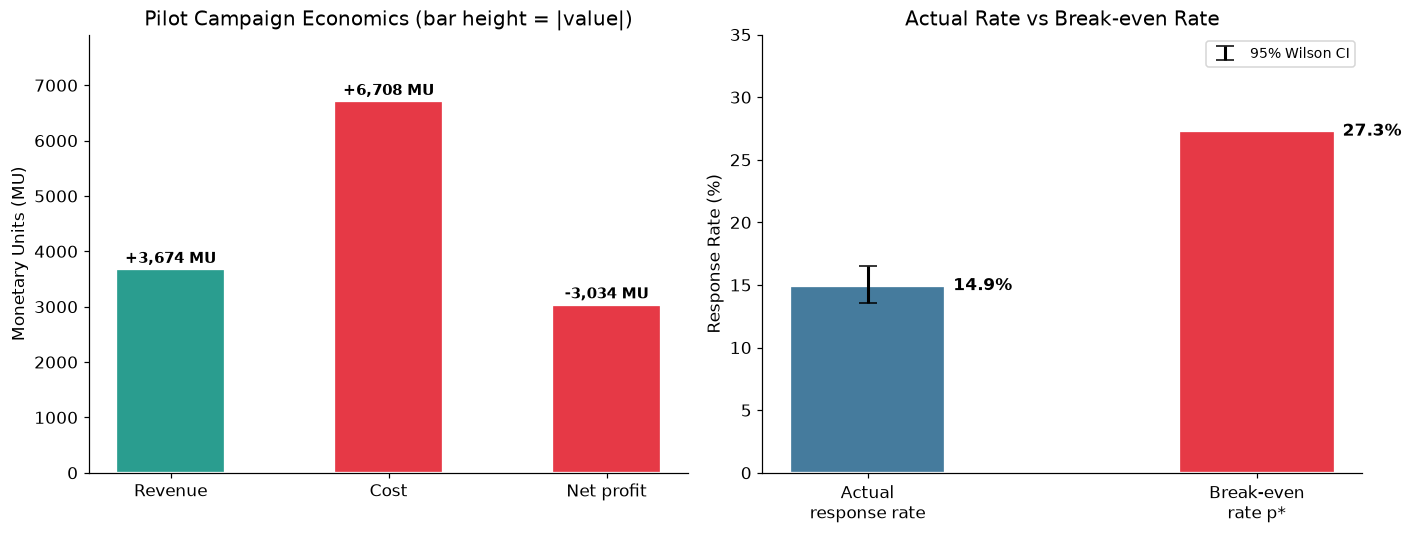

In [5]:
# ── Part (a)(ii): Break-even analysis ────────────────────────────────────────
print("For each contacted customer with response probability p:")
print(f"  E[profit] = p × {REVENUE} − {COST}  >  0   ⇔   p > p* = {COST}/{REVENUE} = {P_STAR:.4f}")
print()
print(f"  Break-even p*            = {P_STAR*100:.2f}%")
print(f"  Observed response rate   = {p_hat*100:.2f}%  (95% CI upper bound {hi*100:.2f}% is still < p*)")
print(f"  Shortfall                = {(P_STAR - p_hat)*100:.2f} percentage points")
print(f"  Average profit / contact = {p_hat:.4f}×{REVENUE} − {COST} = {p_hat*REVENUE-COST:+.4f} MU")
print(f"  × {n:,} contacts          = {n*(p_hat*REVENUE-COST):+,.0f} MU")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ax = axes[0]
vals = [total_revenue, total_cost, total_profit]
bars = ax.bar(['Revenue', 'Cost', 'Net profit'], [abs(v) for v in vals],
              color=['#2a9d8f', '#e63946', '#e63946' if total_profit < 0 else '#2a9d8f'],
              edgecolor='white', lw=1.5, width=0.5)
for b, v in zip(bars, vals):
    ax.text(b.get_x()+b.get_width()/2, b.get_height()+50, f'{v:+,} MU',
            ha='center', va='bottom', fontweight='bold', fontsize=10)
ax.set(title='Pilot Campaign Economics (bar height = |value|)', ylabel='Monetary Units (MU)')
ax.set_ylim(0, max(total_cost, total_revenue)*1.18)

ax = axes[1]
ax.bar(['Actual\nresponse rate', 'Break-even\nrate p*'], [p_hat*100, P_STAR*100],
       color=['#457b9d','#e63946'], edgecolor='white', lw=1.5, width=0.4)
ax.errorbar(0, p_hat*100, yerr=[[(p_hat - lo)*100], [(hi - p_hat)*100]],
            fmt='none', color='black', capsize=6, lw=2, label='95% Wilson CI')
ax.set(ylabel='Response Rate (%)', title='Actual Rate vs Break-even Rate')
ax.set_ylim(0, 35)
ax.legend(fontsize=9)
for i, v in enumerate([p_hat*100, P_STAR*100]):
    ax.text(i + 0.22, v, f'{v:.1f}%', ha='left', va='center', fontweight='bold')
plt.tight_layout()
plt.savefig('plots/pilot_diagnosis.png', dpi=150, bbox_inches='tight')
plt.show()

**Why contacting everyone lost money.** Contacting a customer is profitable in expectation only if their acceptance probability exceeds p* = 3/11 ≈ 27.3 %. The pilot's average response rate was 14.94 % (95 % Wilson CI 13.52–16.47 %), so the *average* customer was well below break-even: each contact earned on average -1.36 MU, and over 2,236 contacts this added up to a loss of 3,034 MU. Blanket contact pays the 3 MU cost for the ~85 % of customers who never accept; the only way to make money is to contact a sub-group whose response probability is above 27.3 %.

---
<a id='part-b'></a>
## Part (b) — Who Responds?

### Choice of tests

* **Categorical attributes** — `Education`, `Marital_Status_Clean` (cleaned 5-level marital status) and `Total_Children` (0/1/2/3 children at home, treated as categorical): χ² test of independence, effect size = bias-corrected **Cramér's V** (Bergsma correction; the plain, uncorrected V is also quoted below for reference).
* **Numerical attributes** — `Income_Clean`, `Recency`, `Total_Spending`, `NumWebVisitsMonth`, `Age`, `Customer_Tenure`. We run **both** Welch's t-test (effect size Cohen's d) and the Mann–Whitney U test (effect size rank-biserial r = 2U/(n₁n₂) − 1 with U computed for responders, so r > 0 means responders have higher values). The normality check below (skewness and Shapiro–Wilk) decides which one is the *primary* test: where the distribution is clearly non-normal / skewed we rely on Mann–Whitney; with n₁ = 334 and n₀ = 1,902 the CLT makes Welch's test on means approximately valid anyway, so agreement between the two is a robustness check.
* **Multiple comparisons** — Holm–Bonferroni over the **9 primary tests** (3 χ² + 6 numeric, each with its primary test chosen above), family-wise α = 0.05. The companion test (Welch or Mann–Whitney) re-tests the same hypothesis, so it is shown as a robustness check with its raw p-value and is not counted as a separate hypothesis.

In [6]:
# ── Part (b)(i)+(ii): Statistical tests + effect sizes ────────────────────────
resp   = df[df['Response'] == 1]
noresp = df[df['Response'] == 0]
n1, n0 = len(resp), len(noresp)
print(f"Responders: {n1}  |  Non-responders: {n0}\n")

CAT_TEST = ['Education', 'Marital_Status_Clean', 'Total_Children']
NUM_TEST = ['Income_Clean', 'Recency', 'Total_Spending', 'NumWebVisitsMonth', 'Age', 'Customer_Tenure']

# Normality / skewness check → choice of primary test
norm_rows = []
for f in NUM_TEST:
    x = df[f].values
    sh_p = shapiro(df[f].sample(n=min(len(df), 2000), random_state=RS))[1]
    s = skew(x)
    primary = 'Mann-Whitney U' if (abs(s) > 0.5 or sh_p < 0.05) else 'Welch t'
    norm_rows.append({'Feature': f, 'skewness': round(s, 3), 'Shapiro p': sh_p, 'Primary test': primary})
norm_df = pd.DataFrame(norm_rows)
print("Normality check (Shapiro–Wilk on 2,000-row sample; skewness on all rows):")
display(norm_df)

results = []
for f in CAT_TEST:
    ct = pd.crosstab(df[f], df['Response'])
    chi2, p, dof, V = cramers_v(ct)
    results.append({'Feature': f, 'Test': 'χ²', 'Stat': chi2, 'df': dof, 'p_raw': p,
                    'Effect_size': V, 'Effect_name': "Cramér's V", 'Primary': True})

for f in NUM_TEST:
    g1, g0 = resp[f].values.astype(float), noresp[f].values.astype(float)
    U, p_mw = mannwhitneyu(g1, g0, alternative='two-sided')   # U for responders
    t, p_t  = ttest_ind(g1, g0, equal_var=False)
    prim = norm_df.set_index('Feature').loc[f, 'Primary test']
    results.append({'Feature': f, 'Test': 'Mann-Whitney U', 'Stat': U, 'df': '—', 'p_raw': p_mw,
                    'Effect_size': rank_biserial(U, len(g1), len(g0)),
                    'Effect_name': 'Rank-biserial r', 'Primary': prim == 'Mann-Whitney U'})
    results.append({'Feature': f, 'Test': 'Welch t', 'Stat': t, 'df': '—', 'p_raw': p_t,
                    'Effect_size': cohens_d(g1, g0), 'Effect_name': "Cohen's d",
                    'Primary': prim == 'Welch t'})

res_df = pd.DataFrame(results)
# Holm–Bonferroni over the family of PRIMARY tests only (3 chi-square + 6 numeric primary = 9).
# The companion test (Welch or Mann-Whitney) re-tests the same hypothesis; it is a robustness check
# and is reported with its raw p-value, not counted as an additional hypothesis.
_m = res_df['Primary'].values
_rej, _adj = holm_bonferroni(res_df.loc[_m, 'p_raw'].tolist())
res_df['p_holm'] = np.nan
res_df['HB_reject'] = None
res_df.loc[_m, 'p_holm'] = _adj
res_df.loc[_m, 'HB_reject'] = _rej
res_df['HB_reject'] = res_df['HB_reject'].astype(object)

def interpret_es(row):
    v = abs(row['Effect_size'])
    if row['Effect_name'] == "Cramér's V":   cuts = (0.10, 0.30, 0.50)
    elif row['Effect_name'] == "Cohen's d":  cuts = (0.20, 0.50, 0.80)
    else:                                    cuts = (0.10, 0.30, 0.50)   # rank-biserial
    return 'Large' if v >= cuts[2] else 'Medium' if v >= cuts[1] else 'Small' if v >= cuts[0] else 'Negligible'
res_df['ES_interpret'] = res_df.apply(interpret_es, axis=1)

med = {f: (resp[f].median(), noresp[f].median()) for f in NUM_TEST}
res_df['Median resp / non-resp'] = res_df['Feature'].map(
    lambda f: f"{med[f][0]:,.0f} / {med[f][1]:,.0f}" if f in med else '')
show = res_df[['Feature','Test','Primary','Stat','p_raw','p_holm','HB_reject',
               'Effect_name','Effect_size','ES_interpret','Median resp / non-resp']]
with pd.option_context('display.float_format', lambda v: f'{v:.4g}'):
    display(show)

# Response rate by category (for practical interpretation)
for f in CAT_TEST:
    print(f"\nResponse rate by {f}:")
    print((df.groupby(f)['Response'].agg(['size','mean'])
             .rename(columns={'size':'n','mean':'resp_rate'})
             .assign(resp_rate=lambda d: (d.resp_rate*100).round(1))).to_string())

Responders: 334  |  Non-responders: 1902

Normality check (Shapiro–Wilk on 2,000-row sample; skewness on all rows):


,Feature,skewness,Shapiro p,Primary test
0,Income_Clean,0.351,3.088531e-17,Mann-Whitney U
1,Recency,-0.004,1.095193e-24,Mann-Whitney U
2,Total_Spending,0.860,3.420212e-38,Mann-Whitney U
3,NumWebVisitsMonth,0.208,4.100076e-28,Mann-Whitney U
4,Age,0.092,1.280430e-14,Mann-Whitney U
5,Customer_Tenure,-0.016,2.234026e-24,Mann-Whitney U


,Feature,Test,Primary,Stat,p_raw,p_holm,HB_reject,Effect_name,Effect_size,ES_interpret,Median resp / non-resp
0,Education,χ²,True,23.01,0.000126,0.0003779,True,Cramér's V,0.09223,Negligible,
1,Marital_Status_Clean,χ²,True,51.64,1.637e-10,6.546e-10,True,Cramér's V,0.146,Small,
2,Total_Children,χ²,True,96.25,9.962e-21,6.973e-20,True,Cramér's V,0.2043,Small,
3,Income_Clean,Mann-Whitney U,True,4.003e+05,2.944e-14,1.472e-13,True,Rank-biserial r,0.2604,Small,"64,044 / 50,522"
4,Income_Clean,Welch t,False,7.147,3.813e-12,NaN,None,Cohen's d,0.4578,Small,"64,044 / 50,522"
5,Recency,Mann-Whitney U,True,2.155e+05,6.464e-21,5.172e-20,True,Rank-biserial r,-0.3214,Medium,30 / 52
6,Recency,Welch t,False,-9.793,1.024e-20,NaN,None,Cohen's d,-0.5688,Medium,30 / 52
7,Total_Spending,Mann-Whitney U,True,4.404e+05,1.578e-29,1.42e-28,True,Rank-biserial r,0.3866,Medium,"1,058 / 315"
8,Total_Spending,Welch t,False,10.85,3.054e-24,NaN,None,Cohen's d,0.7726,Medium,"1,058 / 315"
9,NumWebVisitsMonth,Mann-Whitney U,True,3.229e+05,0.625,0.6911,False,Rank-biserial r,0.0166,Negligible,6 / 6



Response rate by Education:
               n  resp_rate
Education                  
2n Cycle     201       10.9
Basic         54        3.7
Graduation  1126       13.5
Master       370       15.4
PhD          485       20.8

Response rate by Marital_Status_Clean:
                        n  resp_rate
Marital_Status_Clean                
Divorced              231       20.8
Married               864       11.3
Single                486       22.4
Together              578       10.4
Widow                  77       24.7

Response rate by Total_Children:
                   n  resp_rate
Total_Children                 
0                637       26.5
1               1125       10.3
2                421       11.2
3                 53        3.8


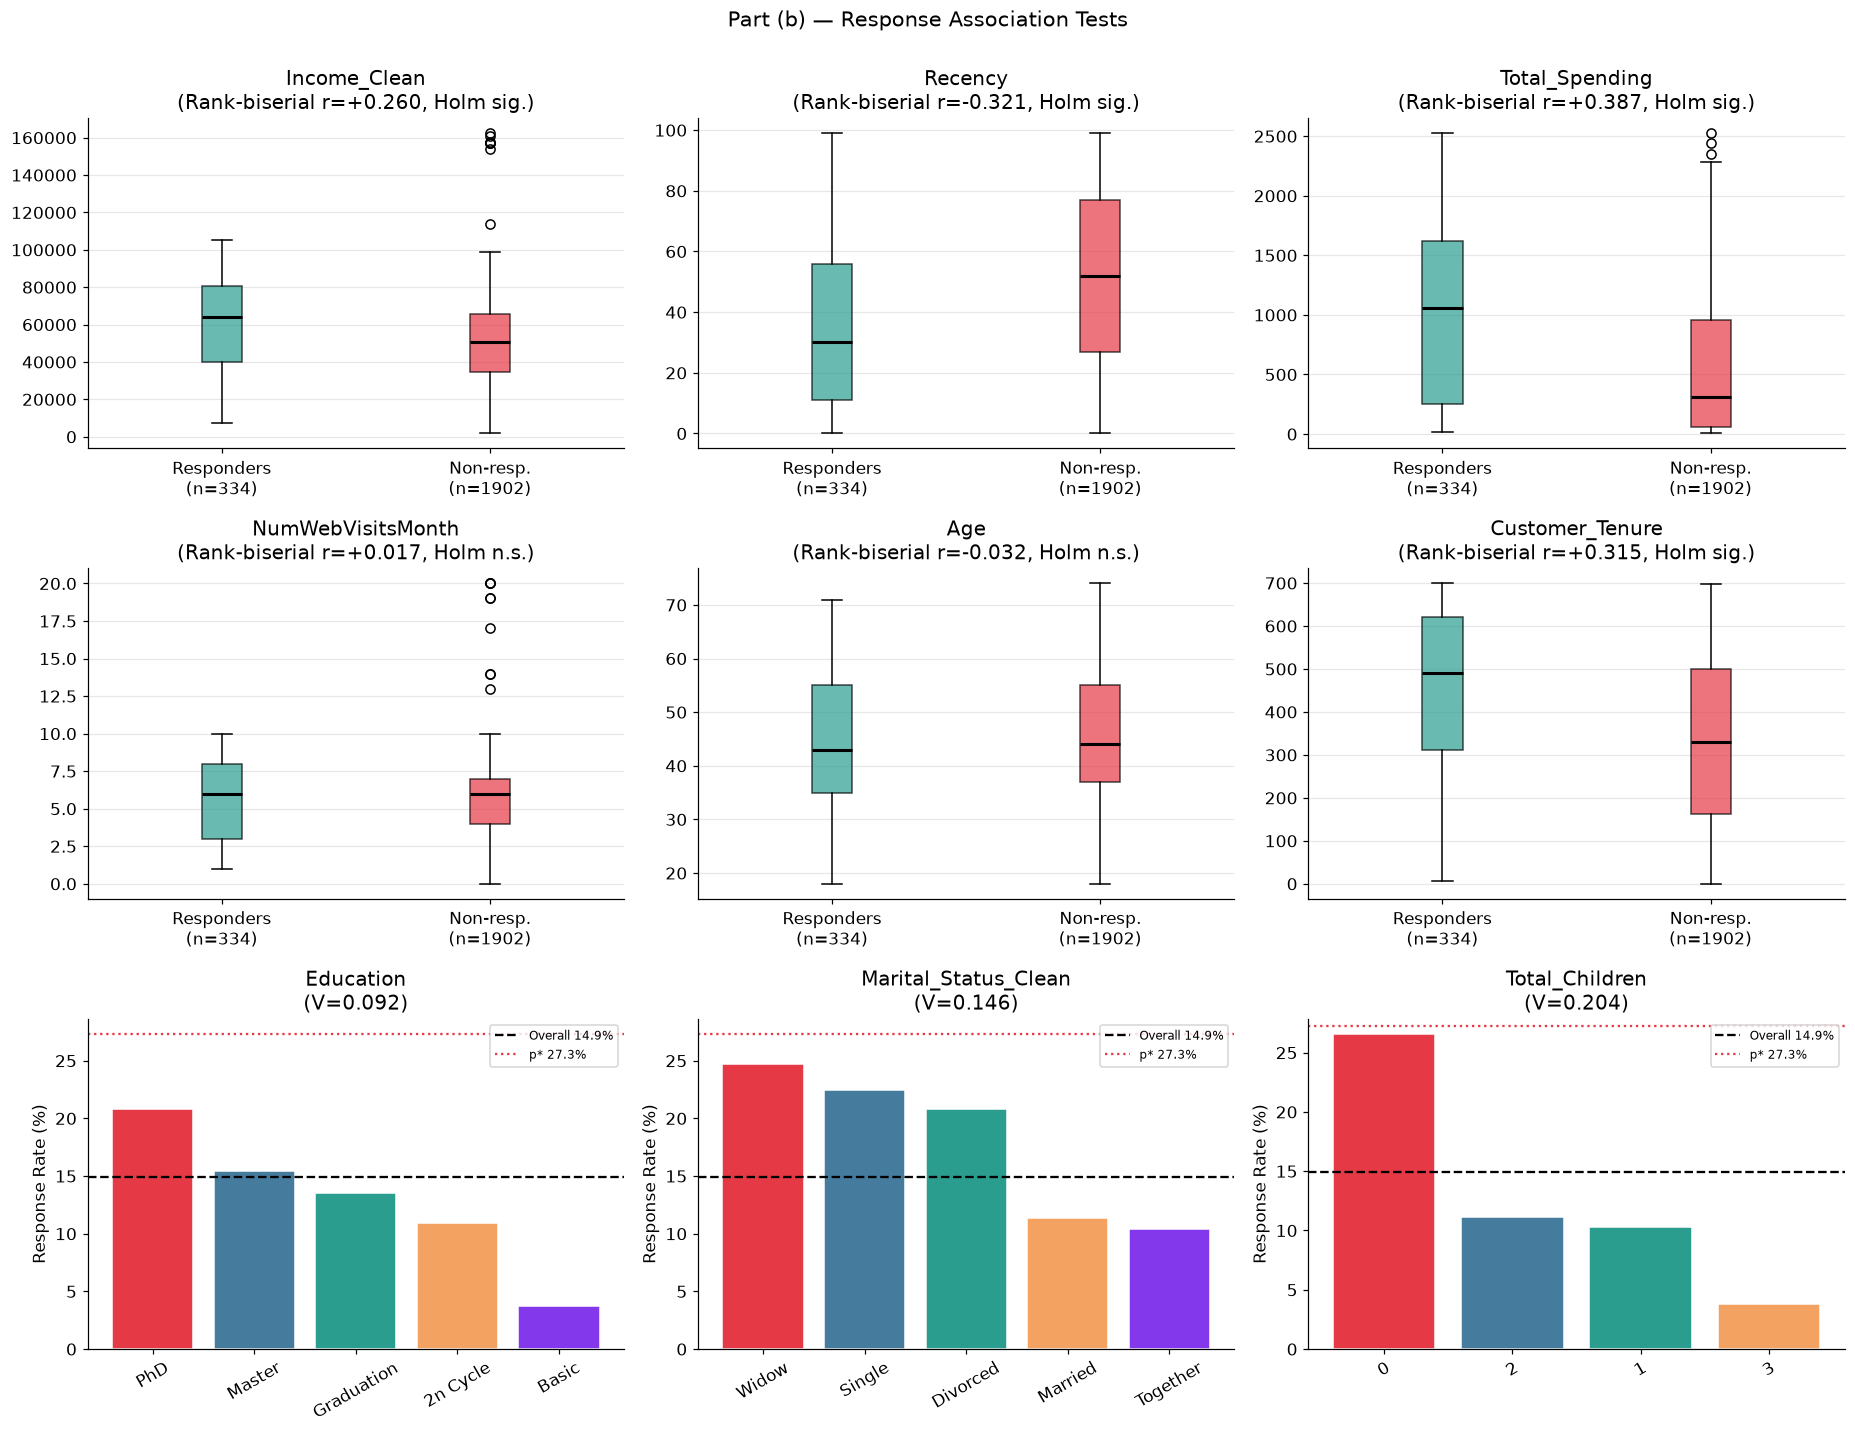

In [7]:
# ── Visualisation: boxplots for numerical, bars for categorical ─────────────────
fig, axes = plt.subplots(3, 3, figsize=(17, 13))
axes = axes.flat
prim = res_df[res_df['Primary']].set_index('Feature')
for i, feat in enumerate(NUM_TEST):
    ax = axes[i]
    bplot = ax.boxplot([resp[feat].values, noresp[feat].values], patch_artist=True,
                       medianprops=dict(color='black', lw=2))
    for patch, color in zip(bplot['boxes'], ['#2a9d8f','#e63946']):
        patch.set_facecolor(color); patch.set_alpha(0.7)
    row = prim.loc[feat]
    sig = 'sig.' if row['HB_reject'] else 'n.s.'
    ax.set_title(f"{feat}\n({row['Effect_name']}={row['Effect_size']:+.3f}, Holm {sig})")
    ax.set_xticks([1, 2])
    ax.set_xticklabels([f'Responders\n(n={n1})', f'Non-resp.\n(n={n0})'])
    ax.grid(axis='y', alpha=0.3)

for j, feat in enumerate(CAT_TEST):
    ax = axes[6 + j]
    rates = df.groupby(feat)['Response'].mean().sort_values(ascending=False)
    ax.bar(rates.index.astype(str), rates.values*100, color=PAL[:len(rates)], edgecolor='white')
    ax.axhline(p_hat*100, color='black', ls='--', lw=1.5, label=f'Overall {p_hat*100:.1f}%')
    ax.axhline(P_STAR*100, color='#e63946', ls=':', lw=1.5, label=f'p* {P_STAR*100:.1f}%')
    ax.set(title=f"{feat}\n(V={prim.loc[feat,'Effect_size']:.3f})", ylabel='Response Rate (%)')
    ax.tick_params(axis='x', rotation=30)
    ax.legend(fontsize=8)

plt.suptitle("Part (b) — Response Association Tests", fontsize=14, y=1.0)
plt.tight_layout()
plt.savefig('plots/response_association_tests.png', dpi=150, bbox_inches='tight')
plt.show()

### Part (b)(iii) — Statistical vs practical significance, and what to tell the CMO

**Statistically significant (Holm–Bonferroni, family of 9 primary tests):** Total_Spending, Recency, Customer_Tenure, Income_Clean (both Mann–Whitney and Welch agree), and all three categorical attributes — Total_Children, Marital_Status_Clean and Education. **Not significant:** Age and NumWebVisitsMonth (Holm-adjusted p = 0.69; |r| < 0.04). Shapiro–Wilk rejects normality for every numerical attribute (with n ≈ 2,000 it rejects even small departures) and Total_Spending is clearly right-skewed (skewness 0.86), so Mann–Whitney is the primary test; Welch's t-test gives the same conclusions for every attribute, so the result does not depend on the choice.

Statistical significance indicates evidence of an association, not necessarily a useful predictive improvement or a causal relationship. These results are descriptive associations from the pilot data and should not be interpreted as evidence that changing an attribute would cause a customer to respond.

**Practically important (effect size, not p-value):**

| Attribute | Effect size | What it means in practice |
|---|---|---|
| Total_Spending | r = +0.39, d = +0.77 (medium) | median spend 1,058 MU for responders vs 315 MU for non-responders; top spending quartile responds at 30.1 % — the only quartile above p* |
| Recency (days since last purchase) | r = −0.32, d = −0.57 (medium) | responders bought **more recently** (median 30 vs 52 days); customers who bought in the last 24 days respond at 26.5 % vs 7.5 % for those inactive 75–99 days |
| Customer_Tenure | r = +0.32 (medium) | longer-standing customers respond more (median 490 vs 331 days) |
| Income_Clean | r = +0.26 (small) | higher income → more response, but largely overlapping with spending |
| Total_Children | V = 0.20 (small) | customers with no children at home respond at 26.5 % vs 10–11 % with 1–2 children |
| Marital_Status_Clean | V = 0.15 (small) | single / divorced / widowed 21–25 % vs married / together 10–11 % |
| Education | V = 0.09 bias-corrected (0.10 uncorrected) — negligible/borderline-small | significant only because n is large; PhD 20.8 % vs others 4–15 % — too weak to act on |

Education is the clearest case of *statistically significant but practically unimportant*. (Uncorrected Cramér's V values are Education 0.101, Marital_Status_Clean 0.152, Total_Children 0.208; the bias-corrected values 0.092 / 0.146 / 0.204 are reported in the table and charts. Both versions lead to the same conclusions.) Note that Recency is "days since last purchase", so its **negative** effect means *recently active* customers respond more (not "frequent visitors").

**Two attributes for the CMO: Total_Spending and Recency.** (1) They have the two largest effect sizes; (2) they are behavioural, already in the CRM, and updated continuously, so they can be used directly to build the contact list; (3) they are largely complementary — *how much* a customer buys and *how recently* — and they are not sensitive personal attributes like marital status or age (see e.v). The chart below shows how sharply the response rate rises across their quartiles.

Total_Spending: response rate by quartile
                  resp_rate_%    n
Total_Spending                    
(4.999, 69.0]             6.0  566
(69.0, 396.5]            12.0  552
(396.5, 1045.5]          11.8  559
(1045.5, 2525.0]         30.1  559 

Recency: response rate by quartile
                resp_rate_%    n
Recency                         
(-0.001, 24.0]         26.5  565
(24.0, 49.0]           14.3  554
(49.0, 74.0]           11.3  567
(74.0, 99.0]            7.5  550 



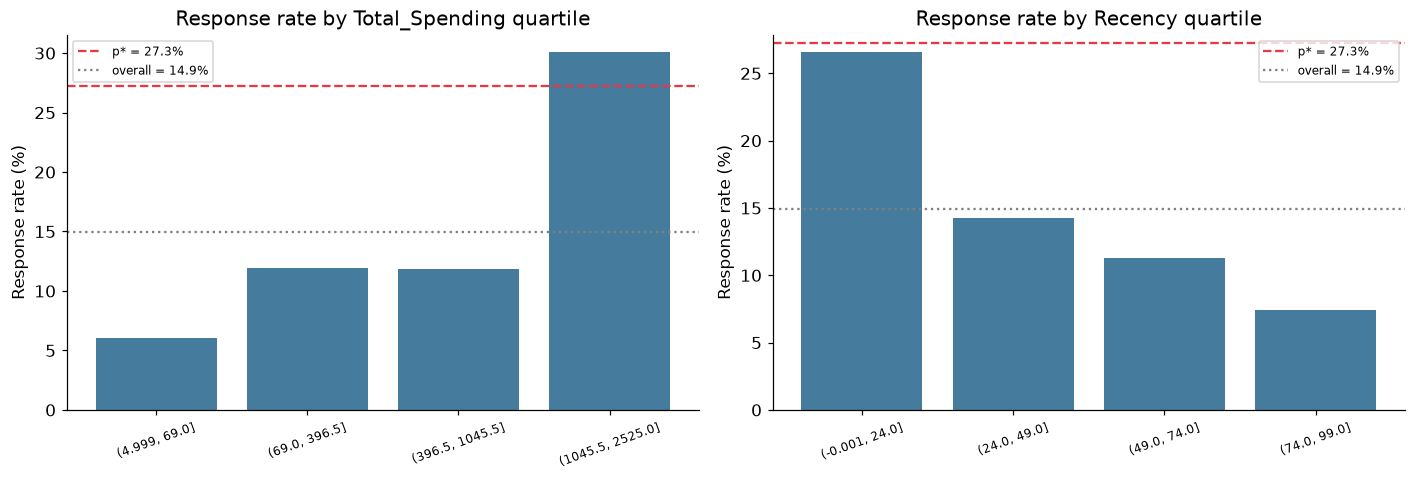

In [8]:
# ── Two attributes for the CMO: response rate by quartile ──────────────────────
CMO_ATTRS = ['Total_Spending', 'Recency']
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, feat in zip(axes, CMO_ATTRS):
    q = pd.qcut(df[feat], 4, duplicates='drop')
    rr = df.groupby(q, observed=True)['Response'].agg(['mean','size'])
    print(f"{feat}: response rate by quartile")
    print((rr.assign(mean=lambda d: (d['mean']*100).round(1))
             .rename(columns={'mean':'resp_rate_%','size':'n'})).to_string(), '\n')
    ax.bar(range(len(rr)), rr['mean']*100, color=PAL[1])
    ax.set_xticks(range(len(rr)))
    ax.set_xticklabels([str(i) for i in rr.index], rotation=20, fontsize=8)
    ax.axhline(P_STAR*100, color='#e63946', ls='--', label=f'p* = {P_STAR*100:.1f}%')
    ax.axhline(p_hat*100, color='grey', ls=':', label=f'overall = {p_hat*100:.1f}%')
    ax.set(title=f'Response rate by {feat} quartile', ylabel='Response rate (%)')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig('plots/cmo_top2_attributes.png', dpi=150, bbox_inches='tight')
plt.show()

---
<a id='part-c'></a>
## Part (c) — Segment-Level View

The cluster labels are the final k = 4 K-Means assignment from Section 2, Task 2, read from `22_cluster_labels.csv` and merged on `ID` (no re-clustering here, so the segments are exactly those described in Section 2). The profile below (cluster means) is used to name the personas.

In [9]:
PROFILE_COLS = ['Age','Income_Clean','Total_Spending','Total_Purchases','Total_Children',
                'Customer_Tenure','Recency','NumWebVisitsMonth','NumDealsPurchases']
profile = df.groupby('cluster')[PROFILE_COLS].mean()
profile['Size'] = df['cluster'].value_counts().sort_index()
with pd.option_context('display.float_format', lambda v: f'{v:,.1f}'):
    display(profile)

,Age,Income_Clean,Total_Spending,Total_Purchases,Total_Children,Customer_Tenure,Recency,NumWebVisitsMonth,NumDealsPurchases,Size
cluster,,,,,,,,,,
0,36.7,"29,470.1",113.1,6.1,1.0,418.7,46.4,7.3,2.2,592
1,45.5,"77,348.5","1,323.1",19.0,0.2,301.6,48.8,2.3,1.2,530
2,49.3,"61,038.2",943.8,19.0,1.0,483.0,49.4,5.9,3.5,518
3,49.5,"43,803.7",164.3,7.6,1.6,223.3,51.8,5.5,2.5,596


In [10]:
# ── Part (c)(i): Per-cluster size, response rate (Wilson CI), expected profit ──
seg_rows = []
for c in sorted(df['cluster'].unique()):
    sub = df[df['cluster'] == c]
    nc, kc = len(sub), int(sub['Response'].sum())
    lo_c, hi_c = wilson_ci(nc, kc)
    seg_rows.append({'Cluster': c, 'Size': nc, 'Responders': kc, 'Resp_Rate': kc/nc,
                     'CI_low': lo_c, 'CI_high': hi_c,
                     'Exp_Profit': kc*REVENUE - nc*COST,          # = nc*(rate*11 − 3)
                     'Profit_per_contact': (kc/nc)*REVENUE - COST})
seg_df = pd.DataFrame(seg_rows).set_index('Cluster')

print(f"{'Cluster':>7} {'Size':>6} {'Resp':>5} {'Rate':>8} {'95% Wilson CI':>18} {'Profit':>10} {'MU/contact':>11}")
for c, r in seg_df.iterrows():
    print(f"{c:>7} {r['Size']:>6,.0f} {r['Responders']:>5.0f} {r['Resp_Rate']*100:>7.2f}% "
          f"[{r['CI_low']*100:5.1f}%, {r['CI_high']*100:5.1f}%] {r['Exp_Profit']:>+10,.0f} {r['Profit_per_contact']:>+11.3f}")
print(f"\nBreak-even p* = {P_STAR*100:.2f}%  →  clusters above p*: {(seg_df['Resp_Rate'] > P_STAR).sum()}")
RESULTS['seg'] = seg_df.reset_index().to_dict(orient='records')

Cluster   Size  Resp     Rate      95% Wilson CI     Profit  MU/contact
      0    592    81   13.68% [ 11.1%,  16.7%]       -885      -1.495
      1    530   133   25.09% [ 21.6%,  29.0%]       -127      -0.240
      2    518    86   16.60% [ 13.6%,  20.1%]       -608      -1.174
      3    596    34    5.70% [  4.1%,   7.9%]     -1,414      -2.372

Break-even p* = 27.27%  →  clusters above p*: 0


In [11]:
# ── Part (c)(ii): Does the response rate differ across clusters? ─────────────
ct_cluster = pd.crosstab(df['cluster'], df['Response'])
chi2_cl, p_cl, dof_cl, V_cl = cramers_v(ct_cluster)
print(f"χ²({dof_cl}) = {chi2_cl:.2f},  p = {p_cl:.3e},  Cramér's V = {V_cl:.3f}")
print("Response rate differs significantly across clusters." if p_cl < 0.05
      else "No significant difference across clusters.")
RESULTS.update(chi2_cl=chi2_cl, dof_cl=dof_cl, p_cl=p_cl, V_cl=V_cl)

χ²(3) = 84.88,  p = 2.754e-18,  Cramér's V = 0.191
Response rate differs significantly across clusters.


In [12]:
# ── Part (c)(iii): Segment-only targeting vs contacting everyone ─────────────
profitable_clusters = seg_df.index[seg_df['Exp_Profit'] > 0].tolist()
if profitable_clusters:
    best_clusters = profitable_clusters
    rule = 'clusters with positive expected profit (response rate > p*)'
else:
    # No segment beats p*; "best" = the cluster(s) with the highest response rate
    # (= least loss per contact).  Contacting it alone still loses money.
    best_clusters = [int(seg_df['Resp_Rate'].idxmax())]
    rule = ('no cluster beats p*, so "best segment" = cluster with the highest response '
            'rate / smallest loss per contact')
print(f"Rule: {rule}\nBest segment(s): {best_clusters}")

seg_mask   = df['cluster'].isin(best_clusters).values
n_target   = int(seg_mask.sum())
k_target   = int(df.loc[seg_mask, 'Response'].sum())
profit_seg = k_target*REVENUE - n_target*COST

print(f"\n{'Policy':<22}{'Contacts':>9}{'Responders':>11}{'Profit (MU)':>13}")
print(f"{'Contact everyone':<22}{n:>9,}{k:>11,}{total_profit:>+13,}")
print(f"{'Contact nobody':<22}{0:>9}{0:>11}{0:>+13}")
print(f"{'Best segment(s) only':<22}{n_target:>9,}{k_target:>11,}{profit_seg:>+13,}")
print(f"\nSegment-only vs everyone: {profit_seg - total_profit:+,} MU "
      f"({'better' if profit_seg > total_profit else 'worse'}); "
      f"segment-only vs nobody: {profit_seg:+,} MU")
RESULTS.update(best_clusters=best_clusters, n_seg=n_target, k_seg=k_target,
               profit_seg=profit_seg, seg_vs_all=profit_seg - total_profit,
               n_profitable_clusters=len(profitable_clusters))

Rule: no cluster beats p*, so "best segment" = cluster with the highest response rate / smallest loss per contact
Best segment(s): [1]

Policy                 Contacts Responders  Profit (MU)
Contact everyone          2,236        334       -3,034
Contact nobody                0          0           +0
Best segment(s) only        530        133         -127

Segment-only vs everyone: +2,907 MU (better); segment-only vs nobody: -127 MU


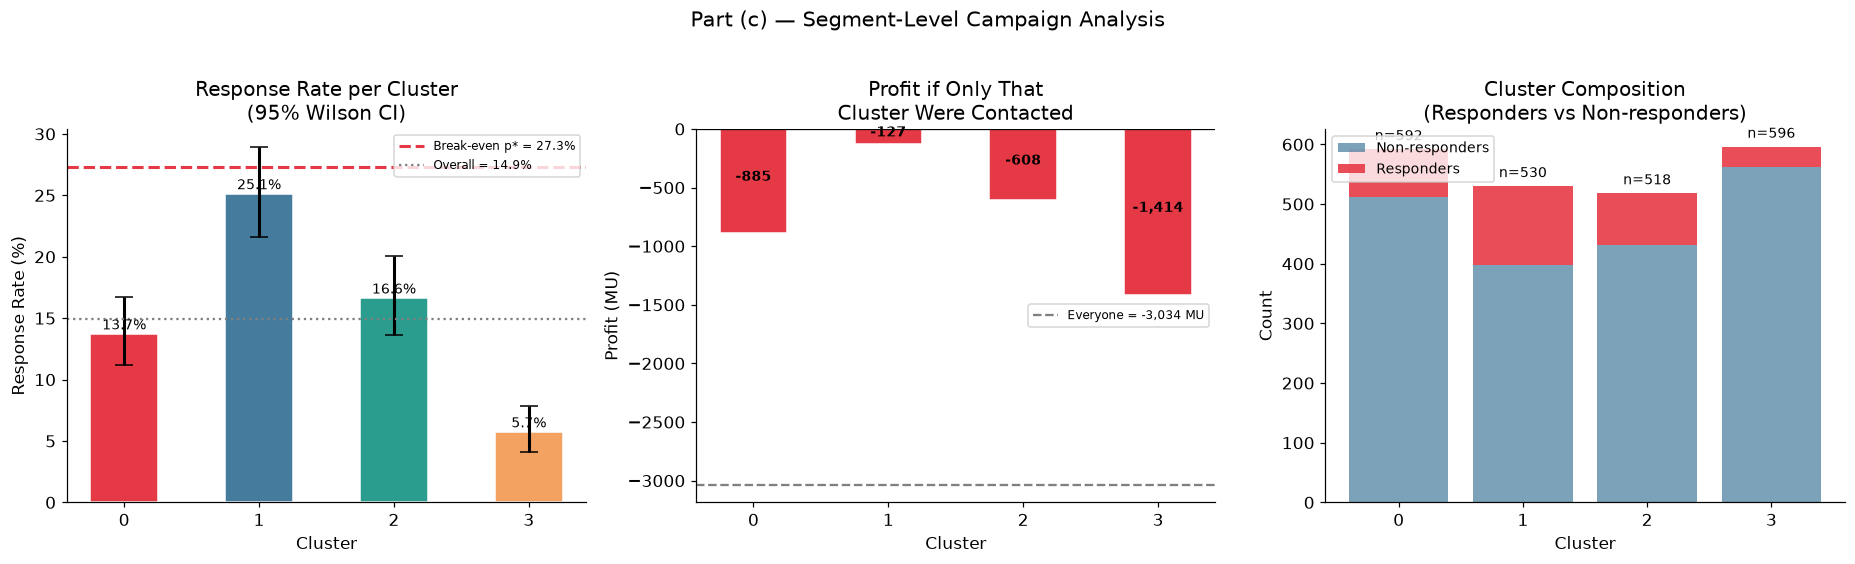

In [13]:
# ── Visualisations ────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
clusters = seg_df.index.astype(str).tolist()
rates = seg_df['Resp_Rate'].values * 100
ax = axes[0]
bars = ax.bar(clusters, rates, color=PAL[:len(clusters)], edgecolor='white', width=0.5)
ax.errorbar(clusters, rates, yerr=[(seg_df['Resp_Rate']-seg_df['CI_low']).values*100,
                                   (seg_df['CI_high']-seg_df['Resp_Rate']).values*100],
            fmt='none', color='black', capsize=6, lw=2)
ax.axhline(P_STAR*100, color='#e63946', ls='--', lw=2, label=f'Break-even p* = {P_STAR*100:.1f}%')
ax.axhline(p_hat*100, color='grey', ls=':', lw=1.5, label=f'Overall = {p_hat*100:.1f}%')
ax.set(xlabel='Cluster', ylabel='Response Rate (%)', title='Response Rate per Cluster\n(95% Wilson CI)')
ax.legend(fontsize=8)
for b, r in zip(bars, rates):
    ax.text(b.get_x()+b.get_width()/2, r+0.4, f'{r:.1f}%', ha='center', fontsize=9)

ax = axes[1]
profits = seg_df['Exp_Profit'].values
bars = ax.bar(clusters, profits, color=['#2a9d8f' if p > 0 else '#e63946' for p in profits],
              edgecolor='white', width=0.5)
ax.axhline(0, color='black', lw=1.5)
ax.axhline(total_profit, color='grey', ls='--', lw=1.5, label=f'Everyone = {total_profit:,} MU')
ax.set(xlabel='Cluster', ylabel='Profit (MU)', title='Profit if Only That\nCluster Were Contacted')
ax.legend(fontsize=8)
for b, p in zip(bars, profits):
    ax.text(b.get_x()+b.get_width()/2, p/2, f'{p:+,.0f}', ha='center', fontsize=9, fontweight='bold')

ax = axes[2]
sizes, rc = seg_df['Size'].values, seg_df['Responders'].values
ax.bar(clusters, sizes - rc, label='Non-responders', color='#457b9d', alpha=0.7)
ax.bar(clusters, rc, bottom=sizes - rc, label='Responders', color='#e63946', alpha=0.9)
ax.set(xlabel='Cluster', ylabel='Count', title='Cluster Composition\n(Responders vs Non-responders)')
ax.legend(fontsize=9)
for c, tot in zip(clusters, sizes):
    ax.text(c, tot+15, f'n={tot}', ha='center', fontsize=9)
plt.suptitle("Part (c) — Segment-Level Campaign Analysis", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('plots/segment_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

### Part (c) — Interpretation

* **Sizes and response rates (95 % Wilson CI):** cluster 0 *Young Budget Browsers* n = 592, 13.7 % [11.1, 16.7] → -885 MU; cluster 1 *Affluent Child-free Big Spenders* n = 530, 25.1 % [21.6, 29.0] → -127 MU; cluster 2 *Loyal Multichannel Deal-Seekers* n = 518, 16.6 % [13.6, 20.1] → -608 MU; cluster 3 *New Budget Families* n = 596, 5.7 % [4.1, 7.9] → -1,414 MU.
* **Differences across clusters:** χ²(3) = 84.9, p = 2.8e-18, Cramér's V = 0.19 — response rates clearly differ, from 5.7 % (New Budget Families) to 25.1 % (Affluent Child-free Big Spenders), but the association is weak-to-moderate.
* **Does segment-only targeting beat contacting everyone?** No cluster has an observed response rate above the break-even threshold of 27.27%. Cluster 1 has the highest observed response rate (25.1%) and the smallest loss per contact (−0.24 MU). Its 95% Wilson confidence interval extends slightly above the break-even threshold, so its true response rate is uncertain. Based on the observed pilot rate, however, contacting this cluster alone would still produce an estimated loss of 127 MU. This is substantially better than contacting everyone (−3,034 MU), but worse than contacting nobody (0 MU; bootstrap CI for this policy [-337, +89] MU includes 0). Segments built for general marketing purposes (without Response) are too coarse to pick out responders: half of all responders sit outside cluster 1. This motivates an individual-level response model. (Cluster 1 was picked as 'best segment' using the same pilot outcomes, so policy 3 is mildly optimistic; that favours the baseline and does not change the conclusion.)

---
<a id='part-d'></a>
## Part (d) — Response Model and Targeting

### Part (d)(i) — Feature availability audit and leakage check

A feature **leaks the target** if its value would not be known *before* the next campaign is sent (it is measured after, or computed from, the response). Every column in `22_marketing_cleaned.csv`, including those engineered in PowerBI / Task 1, is audited:

| Feature(s) | Origin | Available before next campaign? | Decision |
|---|---|---|---|
| `ID` | identifier | yes | drop (no meaning) |
| `Year_Birth`, `Year_Birth_Clean` | raw / cleaned | yes | drop — redundant with `Age` |
| `Age` | engineered (reference year − birth year) | yes | **keep** |
| `Education` | raw | yes | **keep** (one-hot) |
| `Marital_Status` | raw (contains 'YOLO', 'Absurd', 'Alone') | yes | drop — superseded by cleaned version |
| `Marital_Status_Clean` | engineered | yes | **keep** (one-hot) |
| `Income` | raw (24 missing) | yes | drop — duplicate of `Income_Clean` |
| `Income_Clean`, `Income_Imputed` | engineered (imputed value + flag) | yes | **keep** |
| `Kidhome`, `Teenhome` | raw | yes | **keep** |
| `Total_Children` | engineered = Kidhome + Teenhome | yes | drop — exact linear duplicate (used in Part b only) |
| `Dt_Customer` | raw date | yes | drop — encoded by `Customer_Tenure` |
| `Customer_Tenure` | engineered (days since enrolment at the data snapshot) | yes, if recomputed at the send date | **keep** |
| `Recency` | raw (days since last purchase) | yes **provided** it is taken from a snapshot made *before* sending; a purchase triggered by the campaign itself would shorten it | **keep** (assumption: snapshot pre-dates the campaign) |
| `MntWines … MntGoldProds`, `Num*Purchases`, `NumWebVisitsMonth` | raw, last-2-years window | same caveat as Recency: the window must end before the send date, otherwise purchases of the offered product could be counted | **keep** (same assumption) |
| `Total_Spending`, `Total_Purchases` | engineered sums of the above | yes | drop from the model — exact linear duplicates of their components (kept for Part b / profiling) |
| `AcceptedCmp1 … AcceptedCmp5` | outcomes of **previous** campaigns | yes — they are history by the time of the next campaign | **keep** |
| `Complain` | raw (last 2 years) | yes | **keep** |
| `Z_CostContact`, `Z_Revenue` | constants (3 and 11) | yes | drop — zero variance |
| `cluster` | Section 2 labels (no Response used) | yes | not used as a model feature (kept for policy 3) |
| `Response` | **target** | no | target |
| any feature built with `Response` (e.g. a "total campaigns accepted" count that includes the pilot) | engineered | **no — leaks the target** | **remove** |

The cleaned file contains no Response-derived column, so to demonstrate the effect of leakage we construct the typical PowerBI feature `Total_Accepted = AcceptedCmp1 + … + AcceptedCmp5 + Response` (the "number of campaigns accepted" measure that is easy to build by summing all acceptance columns), compare cross-validated ROC-AUC with and without it, and then remove it. The legitimate version `Prev_Accepted = AcceptedCmp1 + … + AcceptedCmp5` uses only prior campaigns and is redundant with its components, so it is not added either.

Before deployment, the CRM must generate a feature snapshot using only information recorded before the campaign contact date. Features such as Recency, spending and purchase counts must be recalculated from that pre-campaign snapshot to prevent temporal leakage.


In [14]:
# ── Feature set (no redundant duplicates) ─────────────────────────────────────
# NOTE: the model uses RAW 'Income' (24 NaN). Its median imputation happens INSIDE each CV
# training fold (SimpleImputer in the pipeline), so no statistic leaks from validation rows.
# 'Income_Clean' (global constant imputation done upstream) is kept only for descriptive Part (b)/(c) work.
CAT_COLS = ['Education', 'Marital_Status_Clean']
NUM_COLS = ['Income', 'Income_Imputed', 'Age', 'Customer_Tenure', 'Kidhome', 'Teenhome',
            'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts',
            'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
            'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
            'AcceptedCmp1', 'AcceptedCmp2', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5',
            'Complain']
DROP_COLS = ['ID', 'Year_Birth', 'Year_Birth_Clean', 'Marital_Status', 'Income_Clean', 'Dt_Customer',
             'Total_Children', 'Total_Spending', 'Total_Purchases', 'Z_CostContact', 'Z_Revenue',
             'cluster', 'Response']
assert set(CAT_COLS + NUM_COLS + DROP_COLS) == set(df.columns), \
    set(df.columns) ^ set(CAT_COLS + NUM_COLS + DROP_COLS)
for c in ['Z_CostContact', 'Z_Revenue']:
    print(f"{c}: unique values = {df[c].unique()}  → constant, dropped")

feature_cols = NUM_COLS + CAT_COLS
X_raw = df[feature_cols].copy()
y     = df['Response'].values.astype(int)
print(f"\nModel features: {len(NUM_COLS)} numeric + {len(CAT_COLS)} categorical")
print(f"Target: Response (1={y.sum()}, 0={len(y)-y.sum()}), imbalance {(len(y)-y.sum())/y.sum():.2f}:1")

def make_prep(num_cols, cat_cols):
    """All preprocessing lives inside the pipeline → fitted only on training folds."""
    return ColumnTransformer([
        ('num', Pipeline([('imp', SimpleImputer(strategy='median')),
                          ('sc',  StandardScaler())]), num_cols),
        ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                          ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat_cols),
    ])

def make_lr(num_cols, cat_cols, class_weight='balanced'):
    return Pipeline([('prep', make_prep(num_cols, cat_cols)),
                     ('clf', LogisticRegression(max_iter=2000, C=1.0, class_weight=class_weight))])

def make_rf(num_cols, cat_cols):
    return Pipeline([('prep', make_prep(num_cols, cat_cols)),
                     ('clf', RandomForestClassifier(n_estimators=300, max_depth=8, min_samples_leaf=3,
                                                    class_weight='balanced', random_state=RS, n_jobs=-1))])

skf = StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=RS)

Z_CostContact: unique values = [3]  → constant, dropped
Z_Revenue: unique values = [11]  → constant, dropped

Model features: 24 numeric + 2 categorical
Target: Response (1=334, 0=1902), imbalance 5.69:1


In [15]:
# ── Leakage demonstration ─────────────────────────────────────────────────────
acc_cols = ['AcceptedCmp1','AcceptedCmp2','AcceptedCmp3','AcceptedCmp4','AcceptedCmp5']
X_leak = X_raw.copy()
X_leak['Total_Accepted'] = df[acc_cols].sum(axis=1) + df['Response']   # includes the target!

leak_rows = []
for name, X_, nums in [('Without leak (clean features)', X_raw, NUM_COLS),
                       ('With leaky Total_Accepted',     X_leak, NUM_COLS + ['Total_Accepted'])]:
    for mname, mk in [('LogReg', make_lr), ('RandomForest', make_rf)]:
        s = cross_val_score(mk(nums, CAT_COLS), X_, y, cv=skf, scoring='roc_auc')
        leak_rows.append({'Feature set': name, 'Model': mname, 'CV ROC-AUC mean': s.mean(), 'sd': s.std()})
leak_df = pd.DataFrame(leak_rows)
display(leak_df.round(4))
RESULTS['leak'] = leak_df.to_dict(orient='records')
print("Total_Accepted is removed: it is not available before the campaign is sent "
      "(it counts the very response we are trying to predict).")

,Feature set,Model,CV ROC-AUC mean,sd
0,Without leak (clean features),LogReg,0.9001,0.0115
1,Without leak (clean features),RandomForest,0.8927,0.0142
2,With leaky Total_Accepted,LogReg,1.0000,0.0000
3,With leaky Total_Accepted,RandomForest,0.9905,0.0028


Total_Accepted is removed: it is not available before the campaign is sent (it counts the very response we are trying to predict).


In [16]:
# ── Leakage screen over EVERY candidate feature: univariate 5-fold CV ROC-AUC ──
# A feature that leaks the target typically separates responders almost perfectly on its own.
# Each feature is fitted alone (median-impute -> scale -> logistic regression) inside the same folds.
screen_cols = NUM_COLS + ['Total_Spending', 'Total_Purchases', 'Total_Children']
X_screen = df[screen_cols].copy()
X_screen['Total_Accepted (incl. Response)'] = X_leak['Total_Accepted']
uni_pipe = Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler()),
                     ('clf', LogisticRegression(max_iter=1000))])
uni = pd.Series({c: cross_val_score(uni_pipe, X_screen[[c]], y, cv=skf, scoring='roc_auc').mean()
                 for c in X_screen.columns}, name='univariate CV ROC-AUC')
uni = uni.reindex((uni - 0.5).abs().sort_values(ascending=False).index)
display(uni.round(3).to_frame())
legit_max = uni.drop('Total_Accepted (incl. Response)').max()
print(f"Highest univariate AUC among legitimate features: {legit_max:.3f} "
      f"({uni.drop('Total_Accepted (incl. Response)').idxmax()})")
print(f"Total_Accepted alone: {uni['Total_Accepted (incl. Response)']:.3f}  -> leaks the target")
RESULTS.update(uni_auc_legit_max=float(legit_max), uni_auc_leak=float(uni['Total_Accepted (incl. Response)']))

,univariate CV ROC-AUC
Total_Accepted (incl. Response),0.958
Total_Spending,0.694
NumCatalogPurchases,0.685
MntMeatProducts,0.681
MntWines,0.662
Recency,0.661
Customer_Tenure,0.657
MntGoldProds,0.649
NumWebPurchases,0.638
Total_Purchases,0.633


Highest univariate AUC among legitimate features: 0.694 (Total_Spending)
Total_Accepted alone: 0.958  -> leaks the target


**Leakage screen.** Every legitimate feature on its own reaches a cross-validated ROC-AUC of at most ≈ 0.69 (Total_Spending; then catalogue purchases, meat and wine spending, Recency, Customer_Tenure at 0.66–0.69). No single legitimate column separates responders almost perfectly, which is what a leaked feature would do. The one feature that does is `Total_Accepted` (it includes the target), at ≈ 0.96 **on its own**. Together with the availability audit above, this shows that no column in the cleaned file leaks the target. The only leak is a Response-derived feature such as `Total_Accepted`, which is removed. The previous-campaign flags `AcceptedCmp1–5` are legitimate (univariate AUC only 0.53–0.62): they are history at the time of the next campaign.

**Leakage result.** Adding `Total_Accepted` (which includes Response) raises the 5-fold CV ROC-AUC of logistic regression from 0.900 to 1.000 (random forest: 0.893 to 0.990). A near-perfect AUC is the signature of leakage: once AcceptedCmp1–5 are known, Total_Accepted − ΣAcceptedCmp *is* the target. The feature can never be computed before the campaign is sent, so it is removed; all results below use the clean feature set.

### Part (d)(ii) — Logistic regression and random forest (stratified 5-fold CV)

All imputation, scaling and one-hot encoding is inside the `Pipeline`, so it is re-fitted on each training fold only. Both main models use `class_weight='balanced'`; an **unweighted** logistic regression is also fitted in the same folds to study calibration in (d)(iii).

In [17]:
models = {'Logistic Regression':     make_lr(NUM_COLS, CAT_COLS),
          'Random Forest':           make_rf(NUM_COLS, CAT_COLS),
          'LogReg (unweighted)':     make_lr(NUM_COLS, CAT_COLS, class_weight=None)}
oof   = {m: np.zeros(len(y)) for m in models}
folds = {m: {'roc': [], 'pr': []} for m in models}

for fold, (tr, va) in enumerate(skf.split(X_raw, y), 1):
    for m, pipe in models.items():
        est = clone(pipe).fit(X_raw.iloc[tr], y[tr])
        oof[m][va] = est.predict_proba(X_raw.iloc[va])[:, 1]
        folds[m]['roc'].append(roc_auc_score(y[va], oof[m][va]))
        folds[m]['pr'].append(average_precision_score(y[va], oof[m][va]))

random_prauc = y.mean()          # PR-AUC of a random classifier = prevalence
rows = []
for m in models:
    rows.append({'Model': m,
                 'ROC-AUC (fold mean ± sd)': f"{np.mean(folds[m]['roc']):.4f} ± {np.std(folds[m]['roc']):.4f}",
                 'PR-AUC (fold mean ± sd)':  f"{np.mean(folds[m]['pr']):.4f} ± {np.std(folds[m]['pr']):.4f}",
                 'ROC-AUC (pooled OOF)': roc_auc_score(y, oof[m]),
                 'PR-AUC (pooled OOF)':  average_precision_score(y, oof[m]),
                 'PR-AUC / random': average_precision_score(y, oof[m]) / random_prauc})
model_df = pd.DataFrame(rows).set_index('Model')
display(model_df.round(4))
print(f"Random-classifier PR-AUC baseline = prevalence = {random_prauc:.4f}")
RESULTS['models'] = model_df.reset_index().to_dict(orient='records')
RESULTS['random_prauc'] = random_prauc

,ROC-AUC (fold mean ± sd),PR-AUC (fold mean ± sd),ROC-AUC (pooled OOF),PR-AUC (pooled OOF),PR-AUC / random
Model,,,,,
Logistic Regression,0.9001 ± 0.0115,0.6567 ± 0.0619,0.9001,0.6451,4.3185
Random Forest,0.8927 ± 0.0142,0.6299 ± 0.0538,0.8928,0.6280,4.2043
LogReg (unweighted),0.8985 ± 0.0111,0.6571 ± 0.0460,0.8981,0.6529,4.3710


Random-classifier PR-AUC baseline = prevalence = 0.1494


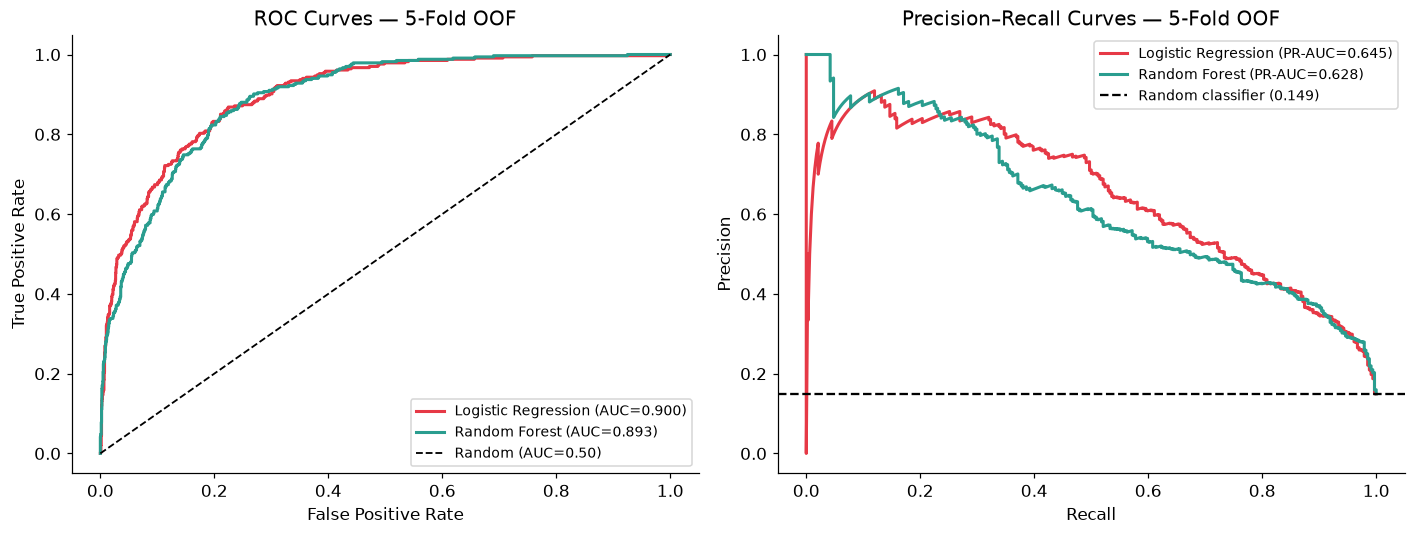

In [18]:
# ── ROC and PR curves ─────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
plot_models = [('Logistic Regression', '#e63946'), ('Random Forest', '#2a9d8f')]
for m, col in plot_models:
    fpr, tpr, _ = roc_curve(y, oof[m])
    axes[0].plot(fpr, tpr, lw=2, color=col, label=f"{m} (AUC={roc_auc_score(y, oof[m]):.3f})")
    prec, rec, _ = precision_recall_curve(y, oof[m])
    axes[1].plot(rec, prec, lw=2, color=col, label=f"{m} (PR-AUC={average_precision_score(y, oof[m]):.3f})")
axes[0].plot([0,1],[0,1],'k--', lw=1.2, label='Random (AUC=0.50)')
axes[0].set(xlabel='False Positive Rate', ylabel='True Positive Rate', title='ROC Curves — 5-Fold OOF')
axes[1].axhline(random_prauc, color='black', ls='--', lw=1.5, label=f'Random classifier ({random_prauc:.3f})')
axes[1].set(xlabel='Recall', ylabel='Precision', title='Precision–Recall Curves — 5-Fold OOF')
for ax in axes: ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig('plots/roc_pr_curves.png', dpi=150, bbox_inches='tight')
plt.show()

### Part (d)(iii) — Cumulative gains, profit curve and threshold

The cumulative gains chart compares how effectively the models rank customers by their out-of-fold predicted response probabilities.

The profit chart presents two complementary views:

1. **Realised profit:** calculated using actual pilot outcomes, \(11y_i-3\), after ranking customers by the selected model's out-of-fold probabilities.
2. **Expected profit:** calculated using predicted probabilities, \(11\hat p_i-3\), after ranking customers by the unweighted Logistic Regression OOF probabilities.

The unweighted Logistic Regression probabilities are used for the expected-profit curve because their average is closer to the observed response prevalence and their reliability diagram indicates better calibration than the class-weighted models.

The theoretical break-even probability is \(p^*=3/11=0.2727\), assuming calibrated probabilities.

The expected and realised profit curves for the unweighted Logistic Regression use the same customer ranking, allowing a like-for-like comparison. The balanced Logistic Regression curve is shown separately because it produces a different ranking and is used for the nested-CV policy evaluation.

Model used for targeting: Logistic Regression
Profit-maximising threshold t* = 0.6108   vs   p* = 0.2727
Contact top 456 customers (20.4%), capturing 241 responders (72.2% of all)
Max realised OOF profit at t*  = +1,283 MU
Realised profit at threshold p*: +595 MU  (942 contacts)
Unweighted LR realised maximum: +1270 MU
Unweighted LR expected maximum: +1346.31 MU
Expected-profit threshold = 0.2732
Theoretical break-even threshold p* = 0.2727


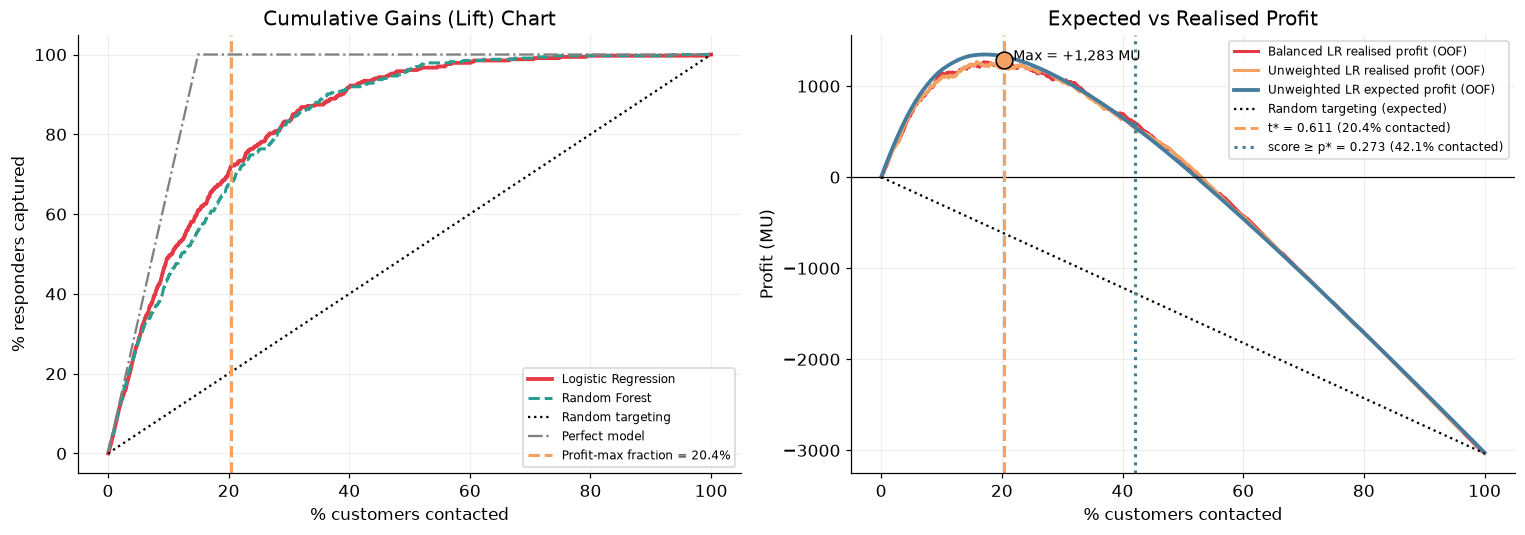

In [19]:
best_model_name = max(['Logistic Regression', 'Random Forest'], key=lambda m: roc_auc_score(y, oof[m]))
other_name      = 'Random Forest' if best_model_name == 'Logistic Regression' else 'Logistic Regression'
oof_best        = oof[best_model_name]
print(f"Model used for targeting: {best_model_name}")

N = len(y)
fractions = np.arange(1, N+1) / N

def profit_curve(scores):
    order = np.argsort(-scores, kind='mergesort')
    ys, ps = y[order], scores[order]
    return np.cumsum(REVENUE*ys - COST), ps, ys

cum_profit, p_sorted, y_sorted = profit_curve(oof_best)
cum_gain = np.cumsum(y_sorted) / y.sum()
opt_idx  = int(np.argmax(cum_profit))
opt_frac, opt_profit, opt_n = fractions[opt_idx], cum_profit[opt_idx], opt_idx + 1
opt_threshold = p_sorted[opt_idx]           # contact everyone with score ≥ t*

# profit if we contacted everybody with score ≥ p*
mask_pstar  = oof_best >= P_STAR
profit_pstar = REVENUE*y[mask_pstar].sum() - COST*mask_pstar.sum()

print(f"Profit-maximising threshold t* = {opt_threshold:.4f}   vs   p* = {P_STAR:.4f}")
print(f"Contact top {opt_n:,} customers ({opt_frac*100:.1f}%), capturing {int(y_sorted[:opt_n].sum())} responders "
      f"({cum_gain[opt_idx]*100:.1f}% of all)")
print(f"Max realised OOF profit at t*  = {opt_profit:+,.0f} MU")
print(f"Realised profit at threshold p*: {profit_pstar:+,} MU  ({int(mask_pstar.sum()):,} contacts)")

# Expected profit curve using approximately calibrated OOF probabilities
p_expected = oof['LogReg (unweighted)']

order_exp = np.argsort(-p_expected, kind='mergesort')
p_exp_sorted = p_expected[order_exp]
y_exp_sorted = y[order_exp]

expected_cum_profit = np.cumsum(REVENUE * p_exp_sorted - COST)
realised_cum_profit = np.cumsum(REVENUE * y_exp_sorted - COST)

# Matched expected and realised profit curves:
# Both use exactly the same unweighted Logistic Regression ranking.
expected_opt_idx = int(np.argmax(expected_cum_profit))
unweighted_realised_opt_idx = int(np.argmax(realised_cum_profit))

print(f"Unweighted LR realised maximum: {realised_cum_profit[unweighted_realised_opt_idx]:+.0f} MU")
print(f"Unweighted LR expected maximum: {expected_cum_profit[expected_opt_idx]:+.2f} MU")

expected_opt_threshold = p_exp_sorted[expected_opt_idx]
expected_opt_profit = expected_cum_profit[expected_opt_idx]

print(f"Expected-profit threshold = {expected_opt_threshold:.4f}")
print(f"Theoretical break-even threshold p* = {P_STAR:.4f}")

RESULTS.update(best_model=best_model_name, t_star=opt_threshold, opt_n=opt_n, opt_frac=opt_frac,
               opt_profit=opt_profit, opt_resp=int(y_sorted[:opt_n].sum()),
               profit_at_pstar=int(profit_pstar), n_at_pstar=int(mask_pstar.sum()),
               expected_opt_threshold=expected_opt_threshold,
               expected_opt_profit=expected_opt_profit,
               unweighted_realised_opt_profit=float(realised_cum_profit[unweighted_realised_opt_idx]))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
ax.plot(fractions*100, cum_gain*100, lw=2.5, color='#e63946', label=best_model_name)
ax.plot(fractions*100, np.cumsum(y[np.argsort(-oof[other_name], kind='mergesort')])/y.sum()*100,
        lw=2, color='#2a9d8f', ls='--', label=other_name)
ax.plot([0,100],[0,100],'k:', lw=1.5, label='Random targeting')
ax.plot(fractions*100, np.cumsum(np.sort(y)[::-1])/y.sum()*100, color='grey', ls='-.', lw=1.5, label='Perfect model')
ax.axvline(opt_frac*100, color='#f4a261', ls='--', lw=2, label=f'Profit-max fraction = {opt_frac*100:.1f}%')
ax.set(xlabel='% customers contacted', ylabel='% responders captured', title='Cumulative Gains (Lift) Chart')
ax.legend(fontsize=8); ax.grid(alpha=0.2)

ax = axes[1]
ax.plot(fractions*100, cum_profit, lw=2, color='#e63946', label='Balanced LR realised profit (OOF)')
ax.plot(fractions*100, realised_cum_profit, lw=2, color='#f4a261', label='Unweighted LR realised profit (OOF)')
ax.plot(fractions*100, expected_cum_profit, lw=2.5, color='#457b9d', label='Unweighted LR expected profit (OOF)')
ax.plot(fractions*100, fractions*N*(p_hat*REVENUE - COST), 'k:', lw=1.5, label='Random targeting (expected)')
ax.axhline(0, color='black', lw=0.8)
ax.axvline(opt_frac*100, color='#f4a261', ls='--', lw=2,
           label=f't* = {opt_threshold:.3f} ({opt_frac*100:.1f}% contacted)')
ax.axvline(mask_pstar.mean()*100, color='#457b9d', ls=':', lw=2,
           label=f'score ≥ p* = {P_STAR:.3f} ({mask_pstar.mean()*100:.1f}% contacted)')
ax.scatter([opt_frac*100], [opt_profit], s=120, zorder=5, color='#f4a261', edgecolors='black')
ax.text(opt_frac*100 + 1.5, opt_profit, f'Max = {opt_profit:+,.0f} MU', fontsize=9)
ax.set(xlabel='% customers contacted', ylabel='Profit (MU)', title='Expected vs Realised Profit')
ax.legend(fontsize=8); ax.grid(alpha=0.2)
plt.tight_layout()
plt.savefig('plots/gains_profit_curve.png', dpi=150, bbox_inches='tight')
plt.show()

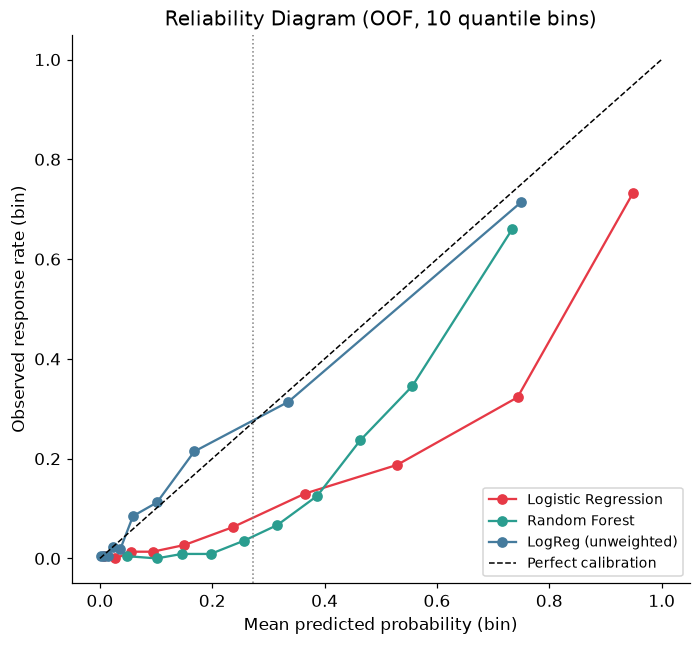

,mean predicted p,observed rate,profit-max threshold t*,contacts at t*,max OOF profit,profit at threshold p*,contacts at p*,Brier,calib slope,calib intercept
Model,,,,,,,,,,
Logistic Regression,0.3159,0.1494,0.6108,456,1283,595,942,0.1245,0.8285,-1.6648
Random Forest,0.3206,0.1494,0.4755,527,1169,78,1173,0.1187,1.9160,-1.1158
LogReg (unweighted),0.1497,0.1494,0.3004,354,1270,1221,385,0.0795,0.9269,-0.0923


In [20]:
# ── Calibration: reliability diagram + threshold of each model ───────────────
from sklearn.metrics import brier_score_loss
fig, ax = plt.subplots(figsize=(6.5, 6))
cal_rows = []
for m, col in [('Logistic Regression','#e63946'), ('Random Forest','#2a9d8f'), ('LogReg (unweighted)','#457b9d')]:
    frac_pos, mean_pred = calibration_curve(y, oof[m], n_bins=10, strategy='quantile')
    ax.plot(mean_pred, frac_pos, 'o-', color=col, label=m)
    cp, ps, _ = profit_curve(oof[m])
    i = int(np.argmax(cp))
    mk = oof[m] >= P_STAR
    _p = np.clip(oof[m], 1e-6, 1-1e-6); _lg = np.log(_p/(1-_p)).reshape(-1, 1)
    _cal = LogisticRegression(C=1e6, max_iter=1000).fit(_lg, y)     # calibration slope / intercept
    cal_rows.append({'Model': m, 'mean predicted p': oof[m].mean(), 'observed rate': y.mean(),
                     'profit-max threshold t*': ps[i], 'contacts at t*': i+1, 'max OOF profit': cp[i],
                     'profit at threshold p*': REVENUE*y[mk].sum() - COST*mk.sum(),
                     'contacts at p*': int(mk.sum()),
                     'Brier': brier_score_loss(y, oof[m]), 'calib slope': _cal.coef_[0][0], 'calib intercept': _cal.intercept_[0]})
ax.plot([0,1],[0,1],'k--', lw=1, label='Perfect calibration')
ax.axvline(P_STAR, color='grey', ls=':', lw=1)
ax.set(xlabel='Mean predicted probability (bin)', ylabel='Observed response rate (bin)',
       title='Reliability Diagram (OOF, 10 quantile bins)')
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig('plots/calibration_reliability.png', dpi=150, bbox_inches='tight')
plt.show()
cal_df = pd.DataFrame(cal_rows).set_index('Model')
display(cal_df.round(4))
RESULTS['calib'] = cal_df.reset_index().to_dict(orient='records')

**Expected vs realised profit curve.**
The expected-profit curve uses out-of-fold predicted probabilities from the unweighted Logistic Regression model, which is closer to the observed response prevalence than the class-weighted model. The realised-profit curve uses actual pilot outcomes. Expected profit represents the model's estimated financial return, whereas realised profit represents what happened in the observed pilot. The theoretical break-even threshold is 27.27% when probabilities are calibrated; differences between the empirical profit-maximising threshold and this value can arise from imperfect calibration and sampling variation. Note that the unweighted model is approximately calibrated, not proven perfectly calibrated; the reliability diagram provides supporting empirical evidence.

**Why t\* differs from p\*: calibration.** p* = 3/11 is the right cut-off only if the scores are *calibrated* probabilities (among customers scored 0.30, 30 % accept). Our main models use `class_weight='balanced'`, which up-weights the 334 responders by ≈ 5.7× during training. That shifts the intercept upward and **inflates** every predicted probability: the balanced logistic regression predicts on average 0.316 while the true response rate is 0.149 (random forest: 0.321); in the reliability diagram both balanced models lie **below** the diagonal. A customer scored 0.30 really accepts far less than 30 % of the time, so cutting at p* would contact too many people (942 contacts, realised profit only +595 MU). The profit curve compensates by moving the cut-off **above** p*: t* = 0.611 for the balanced LR (random forest 0.476). The **unweighted** logistic regression is close to calibrated (mean prediction 0.150 vs 0.149, points near the diagonal) and its profit-maximising threshold is t* = 0.300 ≈ p* = 0.273; contacting its customers with score ≥ p* earns +1,221 MU, almost its maximum of +1,270 MU. So the gap between t* and p* is a calibration artefact of class weighting, not a contradiction of the break-even analysis; with calibrated probabilities (unweighted LR, or Platt/isotonic calibration fitted inside the folds) one can simply contact everyone whose probability exceeds 3/11. Ranking quality (ROC-AUC) is almost identical for the weighted and unweighted LR (0.900 vs 0.898), so only the threshold changes.

**Calibration metrics (OOF).** Calibration slope / intercept (logistic fit of the outcome on logit of the predicted probability; ideal = 1 / 0) and Brier score: unweighted LR 0.93 / −0.09, Brier 0.080 (close to calibrated); balanced LR 0.83 / −1.66, Brier 0.125 (systematic over-prediction caused by class weights); random forest 1.92 / −1.12, Brier 0.119. Note that the *expected*-profit maximiser (0.273) coincides with p\* by construction — sorting by p̂ and adding customers while 11p̂ − 3 > 0 must stop at p\* — so it is not evidence of calibration; the evidence is the reliability diagram, the slope/intercept above, and the *realised*-profit threshold (0.300).

**A policy with no tuned threshold.** Contacting everyone whose unweighted-LR score is ≥ p\* = 3/11 involves no threshold fitted to the data. It contacts 385 customers, reaches 216 responders and earns +1,221 MU (95 % bootstrap CI [+988, +1,461]) — essentially the same as the nested-CV policy (+1,222 MU), which supports using calibrated probabilities with the theoretical cut-off.

### Honest estimate of the model policy — threshold chosen on inner folds

Choosing t* on the same OOF predictions that are then used to report profit is optimistically biased (the threshold is tuned to the noise in those 2,236 outcomes). To get an honest estimate we use **nested cross-validation**: in each outer fold the threshold is chosen by an inner 5-fold CV on the outer-training data only, the model is refit on the outer-training data, and the policy "contact if score ≥ inner-chosen threshold" is applied to the untouched outer-validation customers. The realised profit summed over the five outer folds is the out-of-sample profit of the *procedure*.

In [21]:
def best_threshold(scores, yy):
    order = np.argsort(-scores, kind='mergesort')
    cp = np.cumsum(REVENUE*yy[order] - COST)
    i = int(np.argmax(cp))
    return scores[order][i] if cp[i] > 0 else np.inf      # inf = contact nobody

base_pipe = models[best_model_name]
nested_mask = np.zeros(len(y), dtype=bool)
nested_rows = []
for fold, (tr, va) in enumerate(skf.split(X_raw, y), 1):
    inner = StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=RS + fold)
    inner_oof = np.zeros(len(tr))
    for itr, iva in inner.split(X_raw.iloc[tr], y[tr]):
        est = clone(base_pipe).fit(X_raw.iloc[tr[itr]], y[tr[itr]])
        inner_oof[iva] = est.predict_proba(X_raw.iloc[tr[iva]])[:, 1]
    thr = best_threshold(inner_oof, y[tr])
    est = clone(base_pipe).fit(X_raw.iloc[tr], y[tr])
    s_va = est.predict_proba(X_raw.iloc[va])[:, 1]
    m_va = s_va >= thr
    nested_mask[va] = m_va
    prof = REVENUE*y[va][m_va].sum() - COST*m_va.sum()
    nested_rows.append({'Outer fold': fold, 'inner threshold': thr, 'contacts': int(m_va.sum()),
                        'responders': int(y[va][m_va].sum()), 'realised profit': int(prof)})
nested_df = pd.DataFrame(nested_rows)
display(nested_df.round(4))
n_nest, k_nest = int(nested_mask.sum()), int(y[nested_mask].sum())
profit_nested = REVENUE*k_nest - COST*n_nest
print(f"Nested-CV model policy: {n_nest:,} contacts, {k_nest} responders, realised profit {profit_nested:+,} MU")
print(f"(vs optimistic same-OOF t* profit {opt_profit:+,.0f} MU)")
RESULTS.update(n_nest=n_nest, k_nest=k_nest, profit_nested=int(profit_nested),
               nested_thr_min=float(nested_df['inner threshold'].min()),
               nested_thr_max=float(nested_df['inner threshold'].max()))

,Outer fold,inner threshold,contacts,responders,realised profit
0,1,0.6033,92,43,197
1,2,0.5040,115,51,216
2,3,0.5760,106,54,276
3,4,0.6938,80,47,277
4,5,0.6061,87,47,256


Nested-CV model policy: 480 contacts, 242 responders, realised profit +1,222 MU
(vs optimistic same-OOF t* profit +1,283 MU)


### Part (d)(iv) — Four policies with bootstrap confidence intervals

All profits are **realised** on the pilot outcomes: profit = 11 × (responders contacted) − 3 × (contacts). Policy (4), the recommended model policy, is the nested-CV policy above (each customer scored by a model and threshold that never saw that customer). The same-OOF t* policy is shown for reference only (optimistically biased). 95 % CIs come from 5,000 bootstrap resamples of customers, keeping each customer's contact decision fixed and recomputing 11·Σy[mask] − 3·Σmask.

These bootstrap intervals are conditional on the contact decisions generated by the nested-CV procedure. They quantify sampling uncertainty in customer outcomes while holding those decisions fixed; they do not include the full variability from retraining the model or selecting a new threshold.


In [22]:
oof_tstar_mask = oof_best >= opt_threshold
policy_masks = {
    '(1) Contact everyone':           np.ones(N, dtype=bool),
    '(2) Contact nobody':             np.zeros(N, dtype=bool),
    '(3) Best segment(s) only':       seg_mask,
    '(4) Model policy (nested CV)':   nested_mask,
    'ref: model, t* tuned on OOF':    oof_tstar_mask,
    'ref: unweighted LR, score >= p* (no tuning)': oof['LogReg (unweighted)'] >= P_STAR,
}
rng = np.random.default_rng(RS)
N_BOOT = 5000
boot_idx = rng.integers(0, N, size=(N_BOOT, N))
yb = y[boot_idx]
pol_rows = []
for name, msk in policy_masks.items():
    mb = msk[boot_idx]
    boot = REVENUE*(yb*mb).sum(axis=1) - COST*mb.sum(axis=1)
    prof = REVENUE*y[msk].sum() - COST*msk.sum()
    pol_rows.append({'Policy': name, 'Contacts': int(msk.sum()), 'Responders': int(y[msk].sum()),
                     'Profit (MU)': int(prof), 'CI 2.5%': np.percentile(boot, 2.5),
                     'CI 97.5%': np.percentile(boot, 97.5),
                     'Profit / contact': prof/msk.sum() if msk.sum() else 0.0})
pol_df = pd.DataFrame(pol_rows).set_index('Policy')
display(pol_df.round(2))
RESULTS['policies'] = pol_df.reset_index().to_dict(orient='records')

ci4 = pol_df.loc['(4) Model policy (nested CV)', ['CI 2.5%', 'CI 97.5%']].values
print(f"Recommended model policy: {profit_nested:+,} MU, 95% bootstrap CI [{ci4[0]:+,.0f}, {ci4[1]:+,.0f}] MU")
print(f"Improvement vs contact-everyone: {profit_nested - total_profit:+,} MU")
# Paired bootstrap: model policy minus best-segment policy
d = (REVENUE*(yb*nested_mask[boot_idx]).sum(1) - COST*nested_mask[boot_idx].sum(1)) \
  - (REVENUE*(yb*seg_mask[boot_idx]).sum(1) - COST*seg_mask[boot_idx].sum(1))
print(f"Model − best-segment: {profit_nested - profit_seg:+,} MU, paired 95% CI "
      f"[{np.percentile(d,2.5):+,.0f}, {np.percentile(d,97.5):+,.0f}]")
RESULTS.update(ci4_lo=float(ci4[0]), ci4_hi=float(ci4[1]),
               model_minus_seg_lo=float(np.percentile(d,2.5)), model_minus_seg_hi=float(np.percentile(d,97.5)))

,Contacts,Responders,Profit (MU),CI 2.5%,CI 97.5%,Profit / contact
Policy,,,,,,
(1) Contact everyone,2236,334,-3034,-3397.00,-2671.0,-1.36
(2) Contact nobody,0,0,0,0.00,0.0,0.00
(3) Best segment(s) only,530,133,-127,-337.05,89.0,-0.24
(4) Model policy (nested CV),480,242,1222,965.00,1477.0,2.55
"ref: model, t* tuned on OOF",456,241,1283,1029.97,1535.0,2.81
"ref: unweighted LR, score >= p* (no tuning)",385,216,1221,987.98,1461.0,3.17


Recommended model policy: +1,222 MU, 95% bootstrap CI [+965, +1,477] MU
Improvement vs contact-everyone: +4,256 MU
Model − best-segment: +1,349 MU, paired 95% CI [+1,136, +1,573]


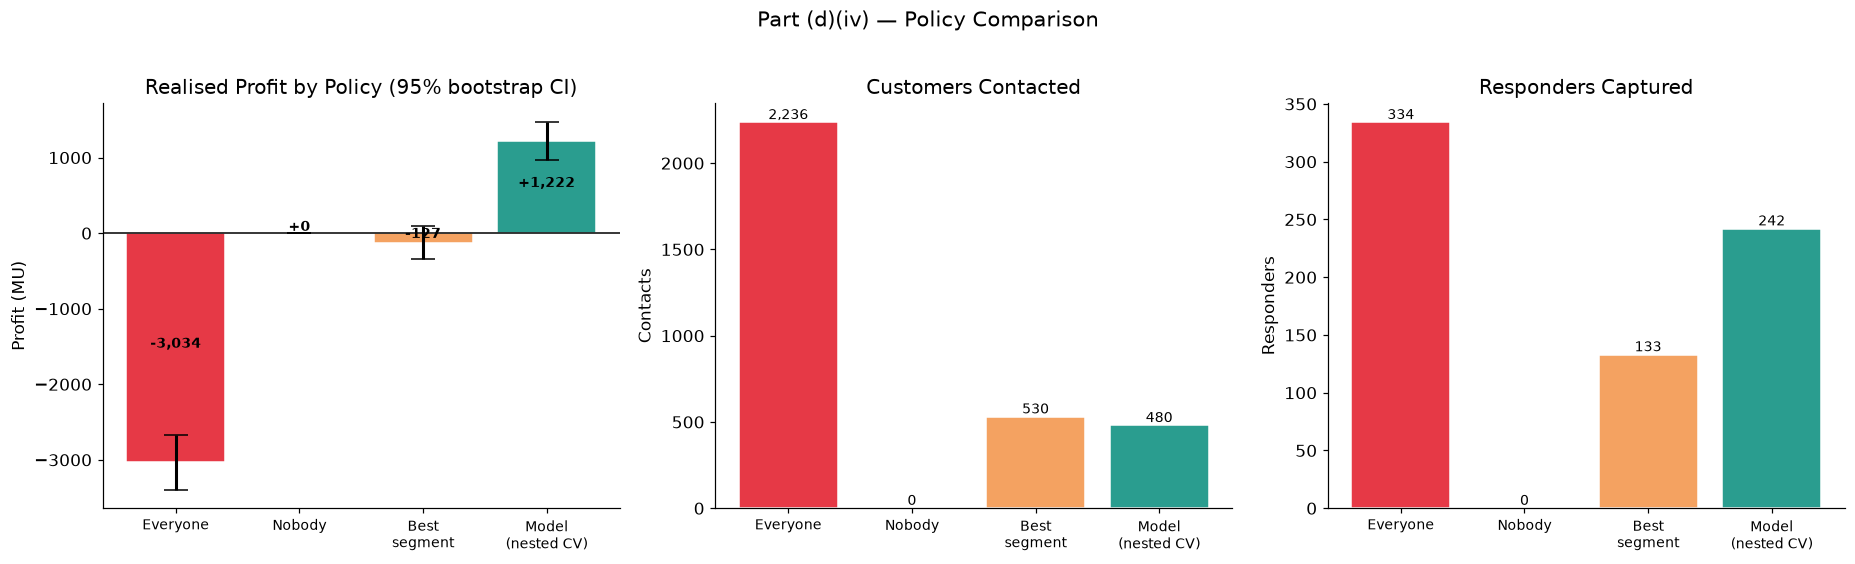

In [23]:
# ── Policy comparison chart ───────────────────────────────────────────────────
plot_df = pol_df.iloc[:4]
labels  = ['Everyone', 'Nobody', 'Best\nsegment', 'Model\n(nested CV)']
colors_bar = ['#e63946','#adb5bd','#f4a261','#2a9d8f']
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
ax = axes[0]
v = plot_df['Profit (MU)'].values
ax.bar(range(4), v, color=colors_bar, edgecolor='white')
ax.errorbar(range(4), v, yerr=[v - plot_df['CI 2.5%'].values, plot_df['CI 97.5%'].values - v],
            fmt='none', color='black', capsize=8, lw=2)
ax.axhline(0, color='black', lw=1)
ax.set(title='Realised Profit by Policy (95% bootstrap CI)', ylabel='Profit (MU)')
for i, val in enumerate(v):
    ax.text(i, val/2 if val else 30, f'{val:+,}', ha='center', fontsize=9, fontweight='bold')
for ax, col, title in [(axes[1], 'Contacts', 'Customers Contacted'),
                       (axes[2], 'Responders', 'Responders Captured')]:
    vals = plot_df[col].values
    ax.bar(range(4), vals, color=colors_bar, edgecolor='white')
    ax.set(title=title, ylabel=col)
    for i, val in enumerate(vals):
        ax.text(i, val, f'{val:,}', ha='center', va='bottom', fontsize=9)
for ax in axes:
    ax.set_xticks(range(4)); ax.set_xticklabels(labels, fontsize=9)
plt.suptitle("Part (d)(iv) — Policy Comparison", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('plots/policy_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

### Ablation — does dropping Age and Marital_Status cost profit? (ethics, e.v)

The memo proposes removing age and marital status from the production model if the profit loss is negligible. We test that with the same nested-CV procedure (same folds, same seeds) and compare who gets targeted.

In [24]:
def nested_policy_mask(num_cols, cat_cols):
    cols = num_cols + cat_cols
    Xs = df[cols].copy()
    pipe = make_lr(num_cols, cat_cols) if best_model_name == 'Logistic Regression' else make_rf(num_cols, cat_cols)
    mask = np.zeros(len(y), dtype=bool)
    for fold, (tr, va) in enumerate(skf.split(Xs, y), 1):
        inner = StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=RS + fold)
        inner_oof = np.zeros(len(tr))
        for itr, iva in inner.split(Xs.iloc[tr], y[tr]):
            e = clone(pipe).fit(Xs.iloc[tr[itr]], y[tr[itr]])
            inner_oof[iva] = e.predict_proba(Xs.iloc[tr[iva]])[:, 1]
        thr = best_threshold(inner_oof, y[tr])
        e = clone(pipe).fit(Xs.iloc[tr], y[tr])
        mask[va] = e.predict_proba(Xs.iloc[va])[:, 1] >= thr
    return mask

# sanity: the same function with the full feature set must reproduce the main nested policy
chk = nested_policy_mask(NUM_COLS, CAT_COLS)
assert (chk == nested_mask).all(), 'nested helper does not reproduce the main policy'

NUM_ABL = [c for c in NUM_COLS if c != 'Age']
CAT_ABL = [c for c in CAT_COLS if c != 'Marital_Status_Clean']
abl_mask = nested_policy_mask(NUM_ABL, CAT_ABL)

def _prof(m): return int(REVENUE*y[m].sum() - COST*m.sum())
mb  = abl_mask[boot_idx]
bootA = REVENUE*(yb*mb).sum(1) - COST*mb.sum(1)
mbF = nested_mask[boot_idx]
bootF = REVENUE*(yb*mbF).sum(1) - COST*mbF.sum(1)
dd = bootA - bootF
print(f"{'Model':<34}{'Contacts':>9}{'Resp':>6}{'Profit':>8}   95% bootstrap CI")
print(f"{'Full features (main policy)':<34}{nested_mask.sum():>9}{y[nested_mask].sum():>6}{_prof(nested_mask):>+8}   [{np.percentile(bootF,2.5):+.0f}, {np.percentile(bootF,97.5):+.0f}]")
print(f"{'Without Age & Marital_Status':<34}{abl_mask.sum():>9}{y[abl_mask].sum():>6}{_prof(abl_mask):>+8}   [{np.percentile(bootA,2.5):+.0f}, {np.percentile(bootA,97.5):+.0f}]")
print(f"Difference (ablated - full): {_prof(abl_mask)-_prof(nested_mask):+d} MU, paired 95% CI [{np.percentile(dd,2.5):+.0f}, {np.percentile(dd,97.5):+.0f}]")

age_band = pd.cut(df['Age'], [0, 35, 50, 65, 120], labels=['<=35', '36-50', '51-65', '>65'])
rows = []
for lab, g in [('Marital_Status_Clean', df['Marital_Status_Clean']), ('Age band', age_band)]:
    t = pd.DataFrame({'full': nested_mask, 'ablated': abl_mask}).groupby(g.values, observed=True).mean()*100
    t.index = [f'{lab}: {i}' for i in t.index]; rows.append(t)
print("\n% of each group targeted:"); display(pd.concat(rows).round(1))
RESULTS.update(abl_contacts=int(abl_mask.sum()), abl_resp=int(y[abl_mask].sum()), abl_profit=_prof(abl_mask),
               abl_ci=[float(np.percentile(bootA,2.5)), float(np.percentile(bootA,97.5))],
               abl_diff_ci=[float(np.percentile(dd,2.5)), float(np.percentile(dd,97.5))])


Model                              Contacts  Resp  Profit   95% bootstrap CI
Full features (main policy)             480   242   +1222   [+965, +1477]
Without Age & Marital_Status            359   206   +1189   [+956, +1414]
Difference (ablated - full): -33 MU, paired 95% CI [-156, +90]

% of each group targeted:


,full,ablated
Marital_Status_Clean: Divorced,26.4,15.2
Marital_Status_Clean: Married,17.4,17.5
Marital_Status_Clean: Single,34.2,17.3
Marital_Status_Clean: Together,13.1,12.8
Marital_Status_Clean: Widow,35.1,19.5
Age band: <=35,27.0,22.2
Age band: 36-50,19.2,14.2
Age band: 51-65,19.7,13.3
Age band: >65,32.5,26.0


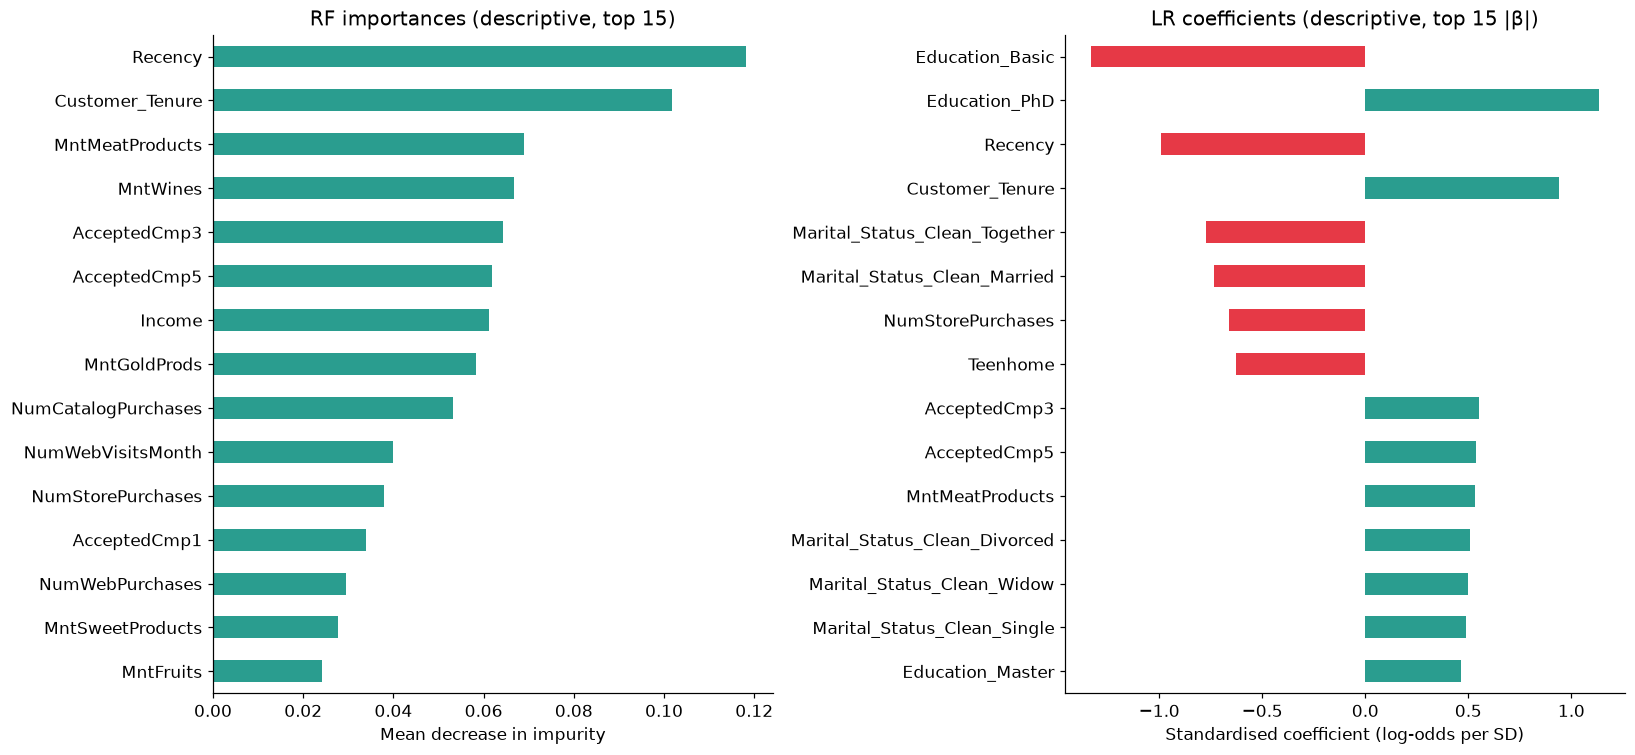

In [25]:
# ── Descriptive only: RF impurity importances and LR coefficients (full data) ──
# These describe what the fitted models rely on; they are NOT causal effects and
# impurity importances are biased toward continuous / high-cardinality features.
rf_full = make_rf(NUM_COLS, CAT_COLS).fit(X_raw, y)
names = rf_full.named_steps['prep'].get_feature_names_out()
names = [s.split('__', 1)[1] for s in names]
imp = pd.Series(rf_full.named_steps['clf'].feature_importances_, index=names).sort_values()
lr_full = make_lr(NUM_COLS, CAT_COLS).fit(X_raw, y)
coef = pd.Series(lr_full.named_steps['clf'].coef_[0], index=names)

fig, axes = plt.subplots(1, 2, figsize=(15, 7))
imp.tail(15).plot.barh(ax=axes[0], color='#2a9d8f')
axes[0].set(xlabel='Mean decrease in impurity', title='RF importances (descriptive, top 15)')
coef.reindex(coef.abs().sort_values().index).tail(15).plot.barh(
    ax=axes[1], color=['#2a9d8f' if c > 0 else '#e63946' for c in coef.reindex(coef.abs().sort_values().index).tail(15)])
axes[1].set(xlabel='Standardised coefficient (log-odds per SD)', title='LR coefficients (descriptive, top 15 |β|)')
plt.tight_layout()
plt.savefig('plots/feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

---
<a id='part-e'></a>
## Part (e) — Who is targeted? Personas and summary

In [26]:
# ── Profile of the customers the model policy would contact ───────────────────
PROF = ['Age','Income_Clean','Total_Spending','Total_Purchases','Total_Children','Customer_Tenure',
        'Recency','NumWebVisitsMonth','NumCatalogPurchases','MntWines','MntMeatProducts']
tg = df.assign(Targeted=np.where(nested_mask, 'Targeted', 'Not targeted'))
prof_t = tg.groupby('Targeted')[PROF].median().T
prof_t['All'] = df[PROF].median()
display(prof_t.round(0))
prev = (df[acc_cols].sum(axis=1) > 0)
print(f"Accepted ≥1 previous campaign: targeted {prev[nested_mask].mean()*100:.1f}%  "
      f"vs not targeted {prev[~nested_mask].mean()*100:.1f}%")
print(f"Response rate: targeted {y[nested_mask].mean()*100:.1f}%  vs not targeted {y[~nested_mask].mean()*100:.1f}%")
ct_t = pd.crosstab(df['cluster'], tg['Targeted'])
ct_t['% of cluster targeted'] = (ct_t['Targeted'] / ct_t.sum(axis=1) * 100).round(1)
ct_t['% of targeted list'] = (ct_t['Targeted'] / ct_t['Targeted'].sum() * 100).round(1)
display(ct_t)
for f in ['Marital_Status_Clean', 'Education']:
    print(f"\n% targeted by {f}:"); print((tg.groupby(f)['Targeted'].apply(lambda s: (s=='Targeted').mean()*100)).round(1).to_string())
RESULTS.update(tgt_prev_acc=float(prev[nested_mask].mean()), ntgt_prev_acc=float(prev[~nested_mask].mean()),
               tgt_rate=float(y[nested_mask].mean()), ntgt_rate=float(y[~nested_mask].mean()),
               tgt_by_cluster=ct_t.reset_index().to_dict(orient='records'),
               tgt_median=prof_t.round(1).to_dict())

Targeted,Not targeted,Targeted,All
Age,44.0,44.0,44.0
Income_Clean,49910.0,62870.0,51371.0
Total_Spending,270.0,1092.0,396.0
Total_Purchases,11.0,17.0,12.0
Total_Children,1.0,1.0,1.0
Customer_Tenure,313.0,502.0,356.0
Recency,55.0,28.0,49.0
NumWebVisitsMonth,6.0,6.0,6.0
NumCatalogPurchases,1.0,4.0,2.0
MntWines,128.0,464.0,174.0


Accepted ≥1 previous campaign: targeted 56.7%  vs not targeted 10.8%
Response rate: targeted 50.4%  vs not targeted 5.2%


Targeted,Not targeted,Targeted,% of cluster targeted,% of targeted list
cluster,,,,
0,477,115,19.4,24.0
1,340,190,35.8,39.6
2,378,140,27.0,29.2
3,561,35,5.9,7.3



% targeted by Marital_Status_Clean:
Marital_Status_Clean
Divorced    26.4
Married     17.4
Single      34.2
Together    13.1
Widow       35.1

% targeted by Education:
Education
2n Cycle      12.9
Basic          3.7
Graduation    19.2
Master        20.5
PhD           33.0


In [27]:
# ── Summary of key numbers (all computed above) ───────────────────────────────
r = RESULTS
md_rows = [
    ('Pilot response rate (95% Wilson CI)', f"{r['p_hat']*100:.2f}% [{r['ci_lo']*100:.2f}%, {r['ci_hi']*100:.2f}%]"),
    ('Pilot cost / revenue / profit', f"{r['cost']:,} / {r['revenue']:,} / {r['profit_all']:+,} MU"),
    ('Break-even p*', f"{P_STAR:.4f} (27.27%)"),
    ('Clusters above p*', f"{r['n_profitable_clusters']} of {len(seg_df)}"),
    ('Response × cluster', f"χ²({r['dof_cl']}) = {r['chi2_cl']:.1f}, p = {r['p_cl']:.2e}, V = {r['V_cl']:.3f}"),
    ('LR / RF ROC-AUC (OOF)', f"{roc_auc_score(y, oof['Logistic Regression']):.3f} / {roc_auc_score(y, oof['Random Forest']):.3f}"),
    ('LR / RF PR-AUC (OOF) vs random', f"{average_precision_score(y, oof['Logistic Regression']):.3f} / {average_precision_score(y, oof['Random Forest']):.3f} vs {random_prauc:.3f}"),
    (f"Profit-max threshold t* ({best_model_name}) vs p*", f"{r['t_star']:.3f} vs {P_STAR:.3f}"),
]
for name, row in pol_df.iterrows():
    md_rows.append((name, f"{row['Contacts']:,} contacts, {row['Responders']} responders, "
                          f"{row['Profit (MU)']:+,} MU [95% CI {row['CI 2.5%']:+,.0f}, {row['CI 97.5%']:+,.0f}]"))
display(Markdown('| Metric | Value |\n|---|---|\n' + '\n'.join(f'| {a} | {b} |' for a, b in md_rows)))

def _clean(o):
    if isinstance(o, dict):  return {str(k): _clean(v) for k, v in o.items()}
    if isinstance(o, list):  return [_clean(v) for v in o]
    if isinstance(o, (np.integer,)):  return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    return o
print('RESULTS_JSON=' + json.dumps(_clean(RESULTS)))

| Metric | Value |
|---|---|
| Pilot response rate (95% Wilson CI) | 14.94% [13.52%, 16.47%] |
| Pilot cost / revenue / profit | 6,708 / 3,674 / -3,034 MU |
| Break-even p* | 0.2727 (27.27%) |
| Clusters above p* | 0 of 4 |
| Response × cluster | χ²(3) = 84.9, p = 2.75e-18, V = 0.191 |
| LR / RF ROC-AUC (OOF) | 0.900 / 0.893 |
| LR / RF PR-AUC (OOF) vs random | 0.645 / 0.628 vs 0.149 |
| Profit-max threshold t* (Logistic Regression) vs p* | 0.611 vs 0.273 |
| (1) Contact everyone | 2,236.0 contacts, 334.0 responders, -3,034.0 MU [95% CI -3,397, -2,671] |
| (2) Contact nobody | 0.0 contacts, 0.0 responders, +0.0 MU [95% CI +0, +0] |
| (3) Best segment(s) only | 530.0 contacts, 133.0 responders, -127.0 MU [95% CI -337, +89] |
| (4) Model policy (nested CV) | 480.0 contacts, 242.0 responders, +1,222.0 MU [95% CI +965, +1,477] |
| ref: model, t* tuned on OOF | 456.0 contacts, 241.0 responders, +1,283.0 MU [95% CI +1,030, +1,535] |
| ref: unweighted LR, score >= p* (no tuning) | 385.0 contacts, 216.0 responders, +1,221.0 MU [95% CI +988, +1,461] |

RESULTS_JSON={"n": 2236, "k": 334, "p_hat": 0.14937388193202147, "ci_lo": 0.13520095113756472, "ci_hi": 0.16474950123705442, "cost": 6708, "revenue": 3674, "profit_all": -3034, "seg": [{"Cluster": 0, "Size": 592, "Responders": 81, "Resp_Rate": 0.13682432432432431, "CI_low": 0.11147264184697261, "CI_high": 0.1668588779988134, "Exp_Profit": -885, "Profit_per_contact": -1.4949324324324325}, {"Cluster": 1, "Size": 530, "Responders": 133, "Resp_Rate": 0.2509433962264151, "CI_low": 0.2159140186055339, "CI_high": 0.2895571364763498, "Exp_Profit": -127, "Profit_per_contact": -0.2396226415094338}, {"Cluster": 2, "Size": 518, "Responders": 86, "Resp_Rate": 0.16602316602316602, "CI_low": 0.13646148578920894, "CI_high": 0.20050188852389564, "Exp_Profit": -608, "Profit_per_contact": -1.1737451737451736}, {"Cluster": 3, "Size": 596, "Responders": 34, "Resp_Rate": 0.05704697986577181, "CI_low": 0.0411076142539835, "CI_high": 0.07865979722493718, "Exp_Profit": -1414, "Profit_per_contact": -2.372483221

### Interpretation and recommended policy

* **The pilot lost money because it contacted everyone:** response 14.94 % (95 % CI 13.52–16.47 %) is far below the break-even 27.3 %, giving -3,034 MU.
* **Segments alone do not fix it:** no Section 2 cluster responds above 27.3 %; the best one (cluster 1, 25.1 %) still loses 127 MU, although that is 2,907 MU better than contacting everyone.
* **An individual response model does:** logistic regression ranks customers well (OOF ROC-AUC 0.900, PR-AUC 0.645 vs 0.149 for a random classifier, ≈ 4.3×); random forest is slightly worse (0.893 / 0.628).
* **Recommended policy (4):** contact roughly the top 20–21 % of customers by model score. Evaluated honestly with nested CV it contacts 480 customers, reaches 242 of the 334 responders (72 %) at a 50.4 % response rate, and earns **+1,222 MU (95 % bootstrap CI [+965, +1,477] MU)** — +4,256 MU versus contacting everyone and +1,349 MU versus the best segment (paired CI [+1,136, +1,573]). A tuning-free alternative (unweighted LR, score ≥ 3/11) earns +1,221 MU with 385 contacts. The same-OOF optimum (+1,283 MU at t* = 0.611) is slightly optimistic, as expected.
* **Ethics check:** removing Age and Marital_Status from the model changes profit by only −33 MU (paired 95 % CI [−156, +90]) and evens out selection rates across marital status (e.g. singles 34 % → 17 %, widowed 35 % → 20 %), so the production model can drop them.
* **Caveats:** the bootstrap CI reflects sampling of customers with fixed contact decisions, not model-refitting variability or a change in customer behaviour between campaigns; the profit is a *response* profit, not an incremental one (see e.iv).

### Personas of the customers to target

The 480 customers selected by the model differ sharply from the rest (medians, targeted vs not targeted): total spending 1,092 vs 270 MU, last purchase 28 vs 55 days ago, tenure 502 vs 313 days, income 62.9k vs 49.9k, 4 vs 1 catalogue purchases, wine 464 vs 128 MU; 57 % accepted at least one earlier campaign (vs 11 %). Their pilot response rate was 50.4 % vs 5.2 % for everyone else. In terms of the Section 2 personas:

1. **Affluent Child-free Big Spenders (cluster 1)** — 40 % of the list; 36 % of this cluster is selected: high-income, wine/meat-heavy catalogue and store buyers who purchased recently and have accepted offers before.
2. **Loyal Multichannel Deal-Seekers (cluster 2)** — 29 % of the list (27 % of the cluster): long-tenure, high-spending web/store shoppers; the model picks those who are recently active and responded to past campaigns.
3. **Engaged members of the Young Budget Browsers (cluster 0)** — 24 % of the list (19 % of the cluster): the minority of this low-spend cluster who bought recently and/or accepted an earlier campaign.

**New Budget Families (cluster 3)** are almost never contacted (6 % of the cluster; they make up the remaining 7 % of the list). The model therefore cuts *across* the clusters: it picks recently active, high-value, previously responsive customers within each segment rather than whole segments, which is why it beats segment-level targeting.

### (e.iv) Response model vs uplift model — measuring incremental profit

Our model predicts **who accepts when contacted**. That is not the same as **who accepts *because* they were contacted**. Some high-scoring customers (loyal, high spenders who already bought in earlier campaigns) might have bought the product anyway through normal channels; contacting them adds cost but little *incremental* revenue. Conversely, a "persuadable" customer with a moderate score may only buy if contacted. An **uplift model** estimates the difference P(accept | contacted) − P(accept | not contacted) and targets the customers for whom that difference × 11 MU exceeds 3 MU.

The pilot contacted everyone, so it contains no untreated customers and cannot estimate uplift. **Next campaign experimental design:** Randomly assign eligible customers to treatment and control groups before sending the campaign. The treatment group receives the offer, while the control group receives no campaign contact. Compare the purchase rates between the two groups, then multiply the difference by the revenue per acceptance and scale it to the treatment population. Subtract the treatment group's contact costs to estimate incremental profit: Incremental Profit = 11 × (response rate_treated − purchase rate_control) × N_treated − 3 × N_treated. Random assignment makes the two groups comparable, isolating the causal uplift and providing training data for a future uplift model.

### (e.v) Ethical and privacy concern

Targeting on **marital status or age** uses personal (and, in some jurisdictions, protected) characteristics; it can feel intrusive, can systematically exclude groups (e.g. widowed or older customers) from offers and discounts, and may conflict with GDPR-style purpose-limitation if the data were collected for a different purpose. **Mitigation:** (1) build the targeting score from behavioural data (purchase history, recency, previous campaign acceptance), which already carries most of the signal, and drop marital status and age from the production model if the loss in profit is negligible; (2) audit the selected list for disparate exclusion rates by age band and marital status before each send; (3) honour opt-outs, document the lawful basis / consent, and keep personal attributes access-controlled. **Evidence:** in the ablation above, a model without age and marital status earns −33 MU less (paired CI [−156, +90], i.e. not distinguishable from zero) and removes most of the gap in selection rates, so we recommend dropping both.

---
## Draft memo to the CMO (≤ 2 pages)

**To:** Chief Marketing Officer  **From:** Analytics team  **Re:** Should we run a second campaign, and to whom?

**1. Recommendation.** Run the second campaign, but **only to the ~480 customers (about 21 % of the base) that our response model ranks highest** — not to everyone. Applying the nested-CV targeting procedure to the pilot customers produced an estimated realised profit of approximately **1,222 MU (conditional 95% bootstrap interval of 965 to 1,477 MU)**, instead of the **3,034 MU loss** the pilot made by contacting all 2,236 customers. This is a retrospective estimate based on pilot outcomes, not a guarantee of future campaign profit. It would have reached 242 of the 334 customers who accepted (72 %) while making 79 % fewer contacts.

**2. Why the pilot lost money.** Each contact costs 3 MU and each acceptance earns 11 MU, so a contact only pays if the customer's chance of accepting is above 3/11 ≈ 27 %. Only 14.94 % of customers accepted (between 13.52 % and 16.47 % with 95 % confidence), so on average every contact lost 1.36 MU. None of our four customer segments reaches 27 % on its own — the best (Affluent Child-free Big Spenders, 25 %) would still have lost a little money — so we need to select individual customers, not whole segments.

**3. Whom to contact (personas).** The selected customers respond at about 50 % (vs 5 % for the rest). They are:
* *Affluent, child-free big spenders* (≈ 40 % of the list): high income, large wine/meat and catalogue purchases, bought recently.
* *Loyal multichannel shoppers* (≈ 29 %): long-standing customers who buy regularly online and in store.
* *Recently active younger customers* (≈ 24 %): lower spenders who have shopped recently and said yes to an earlier campaign.
* A small remainder (≈ 7 %) comes from the New Budget Families segment.

What they share: they **spent a lot in the last two years**, **bought recently** (median 28 days ago vs 55 for others), have been customers longer, and more than half accepted a previous campaign. Spending and recency are the two attributes we recommend the marketing team keeps an eye on. Customers with low spending and no recent purchases — especially new budget families — should not be contacted.

**4. Risks and assumptions.**
* The estimate assumes the next campaign's offer, costs (3 MU) and revenue (11 MU), and customer behaviour are similar to the pilot's. A different product or season can change response rates.
* The confidence range reflects random variation among customers; real-world uncertainty is larger. Expect a result in the high hundreds to low thousands of MU, not an exact figure.
* Purchase data must be taken from a snapshot *before* the campaign is sent; otherwise the model would be using information it will not have.
* Customers who said yes may partly have bought anyway (see 5) — the true *extra* profit may be lower than the figure above.
* The model must be refreshed after each campaign and its list checked before sending.

**5. "Who responds" is not "who responds because we called."** Our model finds customers likely to say yes when contacted. Some of them — loyal big spenders — might have bought the product anyway, so contacting them costs 3 MU for little extra revenue. To measure what the campaign really adds, randomly assign eligible customers to treatment and control groups before sending the campaign. The treatment group receives the offer, while the control group receives no campaign contact. Compare the purchase rates between the two groups, then multiply the difference by the revenue per acceptance and scale it to the treatment population. Subtract the treatment group's contact costs to estimate incremental profit. Over time, this data enables an uplift model targeting customers whose behaviour is genuinely changed by the contact.

**6. Ethics and privacy.** Selecting customers by marital status or age can feel intrusive, may unfairly exclude groups (for example widowed or older customers) from offers, and may not be a permitted use of the data. We recommend building the contact list mainly from **purchase behaviour** (spending, recency, past responses), which already carries most of the signal, checking each list for unusual exclusion of age or marital-status groups, and respecting opt-outs and consent rules. In our test, dropping both attributes cost only about 33 MU (not distinguishable from zero), so we recommend dropping them.

**Decision requested:** approve a targeted second campaign to the model-selected list (~480 customers), with a randomized hold-out group to measure incremental profit.